# Module 2 — Task 1: Predict the Probability of Default

**Brief (verbatim):**
> **Task 1: Predict Probability of Default**
> Target: Default_Flag
> Build models, evaluate performance

**The business problem (brief):** *"NovaFin wants to increase lending while reducing defaults."* Management asks which loans to approve, reject or send for manual review.

**Where this task sits:** Data → **PD model (this task)** → PD per loan and risk bands (Task 2) → Expected Credit Loss and the Approve / Review / Reject decision (Task 3).

- **PD (Probability of Default):** the chance, from 0 to 1, that a borrower fails to repay.
- **Default_Flag:** 1 = the borrower defaulted, 0 = repaid as agreed.

**The question this notebook answers honestly: can a model built on borrower fundamentals predict default better than the bank already does?**

The bank already has a view of each borrower's risk: the **interest rate it charged**. Riskier borrowers pay more. So we run a **champion vs challenger** test (decision M2-09):

- **Champion:** the bank's own risk view, i.e. the interest rate alone.
- **Challengers:** our models, built only on the borrower's fundamentals (income, debt, credit score, collateral, ...).
- A challenger adds value only if it beats the champion, in ML terms **and** in rupees, on loans it has never seen. If none does, we say so.

| Step | What it does |
| --- | --- |
| 0 | Setup |
| 1 | Know the data: checks, default rate across each input, the loan book in ₹, collateral, loan term |
| 2 | The 15 inputs, the leakage check, and why Interest_Rate is not an input |
| 3 | Train / test split: 4,000 loans to build and compare, 1,000 locked away for the final exam |
| 4 | Champion and reference |
| 5 | Challengers: 25 rounds of cross-validation, measures with formulas |
| 5b | Why we don't rebalance defaults (evidence) |
| 5c | Overfitting check |
| 6 | Choosing the challenger: the agreed rule step by step; every model against the chosen one on unseen loans |
| 7 | The ₹ case: losses at the same approval level and where the advantage turns, extra lending, mispriced loans |
| 8 | Final exam on the 1,000 test loans: bootstrap ranges and the DeLong test |
| 8b | One model for both segments? Retail vs Corporate and sector risk: profiles, model performance in each, and one model vs separate models |
| 9 | Explaining the model: weights, odds ratios, SHAP, example loans in ₹ |
| 10 | What the results say: ML case, finance case, hand-off to Task 2 |
| 11 | Save the outputs |

**Decisions used** (all in `docs/decisions.md`):
- M2-01: Loan_ID as the identifier;
- M2-07: split and cross-validation;
- M2-09: champion vs challenger;
- M2-10: the first look at the data;
- M2-11: the 15 inputs;
- M2-12: no rebalancing;
- M2-13: models and the selection rule.

**Runs on its own or from `run_module_2.ipynb`.** It loads everything it needs itself.

**Helpers used:**
- `helpers/m02_data.py`: data, the four ratios, the input list;
- `helpers/m02_style.py`: chart style.

## 0. Setup

Works locally and in Google Colab.
- **Colab:** upload the whole unzipped project folder (any name) to Google Drive; the cell below finds it. Then run all cells.
- The full run takes about 9 minutes: 7 models are each trained 25 times, and three of them also tune their settings inside each round.

In [1]:
import os
import sys
import json
import time
import warnings
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_02_credit_risk"
OUT_DIR = MODULE_DIR / "outputs" / "task1"            # tables, charts, predictions, chosen model
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(MODULE_DIR / "helpers"))       # make the Module 2 helpers importable

# ---- Quieter output ----------------------------------------------------------------------
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")      # avoids a Windows CPU-count warning from joblib
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# ---- Libraries ---------------------------------------------------------------------------
import numpy as np                    # maths on arrays
import pandas as pd                   # tables
import matplotlib.pyplot as plt       # charts
import joblib                         # saves the fitted model for Task 2
import shap                           # SHAP explanations (step 9)
from scipy import stats               # t-distribution and normal distribution for the 95% ranges

# scikit-learn: the standard Python machine-learning library
from sklearn.pipeline import Pipeline                       # chains preparation + model, fitted together
from sklearn.compose import ColumnTransformer               # different preparation for different columns
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
                                     GridSearchCV)
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, brier_score_loss, log_loss,
                             precision_score, recall_score, f1_score)
from lightgbm import LGBMClassifier                         # gradient boosting (LightGBM library)

# ---- Module 2 helpers --------------------------------------------------------------------
from m02_data import load_loans, add_ratios, data_report, RATIO_FORMULAS, GIVEN_INPUTS, MODEL_INPUTS
from m02_style import apply_style, SURFACE, INK, INK_2, GRID, BLUE, ORANGE, AQUA
apply_style()
plt.close("all")                      # start clean when run from the module runner

SEED = 42                             # one fixed random seed everywhere (project decision P-06)
LGD = 0.40                            # loss given default: share of the loan lost if the borrower defaults
                                      # (the brief's assumption, decision M2-03); used here only to show PD in ₹
CRORE = 1e7                           # 1 crore = 1,00,00,000 rupees
LAKH = 1e5                            # 1 lakh  = 1,00,000 rupees
pd.set_option("display.width", 200, "display.max_columns", 30)


def save_table(table: pd.DataFrame, name: str, keep_index: bool = False) -> None:
    """Save a table to outputs/task1/<name>.csv."""
    table.to_csv(OUT_DIR / f"{name}.csv", index=keep_index)


def save_chart(fig, name: str) -> None:
    """Save a chart to outputs/task1/<name>.png at print quality."""
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Project folder found")
print("Outputs go to: ", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())

Project folder found
Outputs go to:  module_02_credit_risk/outputs/task1


## 1. Know the data

Before any model, the Board and the evaluator need to trust the data (decision M2-10). This step:
- runs quality checks;
- shows how the default rate moves across each input;
- shows the loan book in rupees;
- looks at collateral and loan term.

**This look is for understanding only.** The model inputs were fixed in advance from credit reasoning (step 2), not picked from the strongest links seen here. Picking inputs after seeing which ones look strongest would flatter the model.

### 1a. Quality checks

In [2]:
# Load the loans through the shared helper: it checks the columns, makes Loan_ID the identifier
# (renamed from Customer_ID if needed, decision M2-01) and checks one row per loan.
loans = add_ratios(load_loans())          # + the four lending ratios (step 2 explains them)

report = data_report(loans)               # rows, missing values, duplicates, default rate, ...
display(pd.DataFrame({"Check": list(report), "Result": [str(v) for v in report.values()]}))

# Plausibility checks: every value must be possible in real lending.
checks = {
    "Credit_Score within 300–900 (Indian bureau scale)": loans.Credit_Score.between(300, 900).all(),
    "Debt_to_Income between 0 and 1": loans.Debt_to_Income.between(0, 1).all(),
    "Interest_Rate between 0% and 30%": loans.Interest_Rate.between(0, 30).all(),
    "Past_Default and Default_Flag are 0/1": loans[["Past_Default", "Default_Flag"]].isin([0, 1]).all().all(),
    "Loan_Term_Months is a whole number of years": (loans.Loan_Term_Months % 12 == 0).all(),
    "Money columns positive": (loans[["Annual_Income", "Existing_Loan", "Loan_Amount",
                                      "Collateral_Value"]] > 0).all().all(),
}
display(pd.DataFrame({"Plausibility check": list(checks), "Passed": list(checks.values())}))
assert all(checks.values()), "a plausibility check failed: inspect before modelling"

,Check,Result
0,rows,5000
1,missing_values,0
2,duplicate_rows,0
3,default_rate,0.199
4,customer_type,"{'Retail': 3694, 'Corporate': 1306}"
5,loan_book_crore,639.7
6,credit_score_range,"(406, 850)"
7,debt_to_income_above_1,0
8,negative_money_values,0


,Plausibility check,Passed
0,Credit_Score within 300–900 (Indian bureau scale),True
1,Debt_to_Income between 0 and 1,True
2,Interest_Rate between 0% and 30%,True
3,Past_Default and Default_Flag are 0/1,True
4,Loan_Term_Months is a whole number of years,True
5,Money columns positive,True


### 1b. How the default rate moves across each input

Each number input is cut into **five equal-sized groups (quintiles)**, from lowest to highest values. For each group:

```text
Default rate = defaulted loans in the group ÷ loans in the group      (whole book: 19.9%)
```

A rising or falling line means the input carries risk information.

**Interest_Rate** is shown too, but it is the **bank's own risk view**, i.e. the champion (step 4), and not a model input.

,Input,Lowest group,Highest group,Gap (highest − lowest),Rates by group (low → high)
0,Interest_Rate,8.5%,41.9%,+33.4%,8.5% · 10.5% · 17.3% · 21.8% · 41.9%
1,Credit_Score,31.8%,10.0%,-21.9%,31.8% · 22.7% · 19.9% · 15.0% · 10.0%
2,Debt_to_Income,11.4%,32.5%,+21.1%,11.4% · 16.4% · 19.1% · 20.4% · 32.5%
3,Past_Default,17.7%,37.8%,+20.1%,0: 17.7% · 1: 37.8%
4,Loan_Amount,13.3%,31.0%,+17.7%,13.3% · 17.0% · 18.4% · 20.0% · 31.0%
5,Total_Debt_to_Income,12.4%,29.7%,+17.3%,12.4% · 16.1% · 20.6% · 20.9% · 29.7%
6,Loan_to_Income,13.2%,28.7%,+15.5%,13.2% · 15.0% · 18.6% · 24.2% · 28.7%
7,Collateral_Value,12.6%,26.9%,+14.3%,12.6% · 16.5% · 20.3% · 23.4% · 26.9%
8,Principal_to_Income,14.0%,23.3%,+9.3%,14.0% · 16.5% · 21.3% · 24.6% · 23.3%
9,Existing_Loan,17.7%,24.1%,+6.4%,17.7% · 17.6% · 19.5% · 20.8% · 24.1%


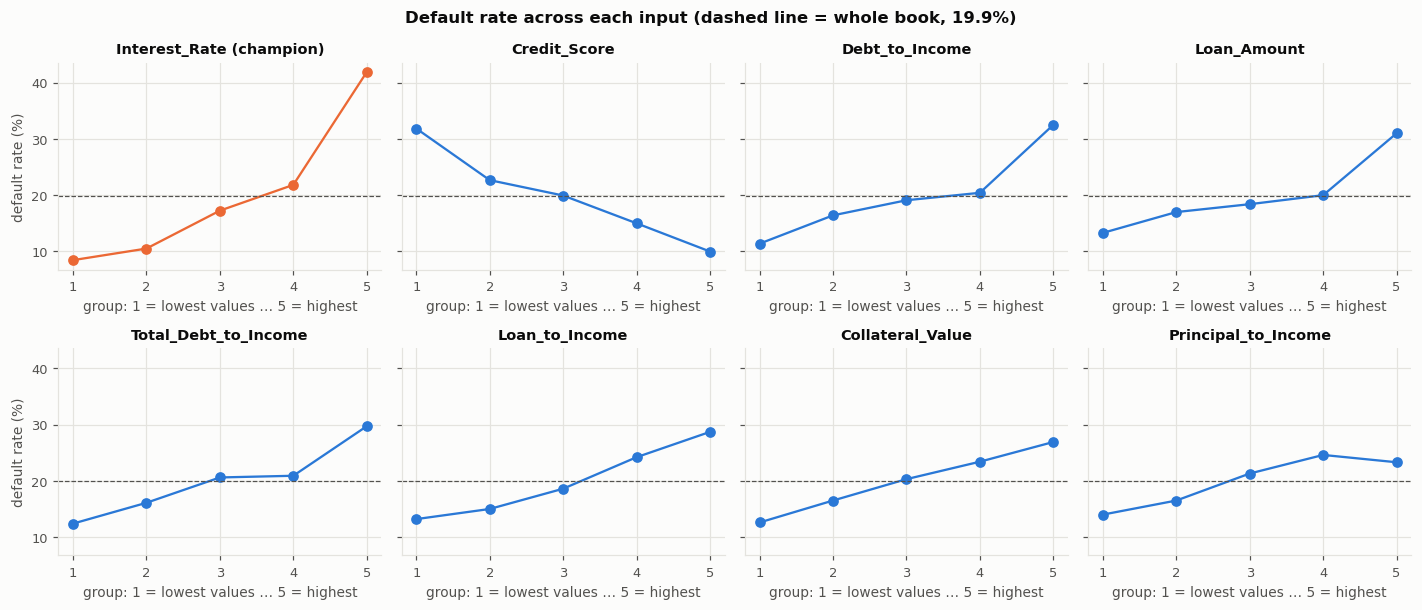

In [3]:
y_all = loans["Default_Flag"]
NUM_LOOK = ["Credit_Score", "Debt_to_Income", "Annual_Income", "Employment_Length", "Loan_Amount",
            "Loan_Term_Months", "Collateral_Value", "Existing_Loan", "Sector_Risk",
            "Loan_to_Value", "Loan_to_Income", "Total_Debt_to_Income", "Principal_to_Income", "Interest_Rate"]

rows = []
for col in NUM_LOOK:
    # qcut = equal-sized groups; duplicates="drop" handles columns with repeated values (e.g. term)
    groups = pd.qcut(loans[col], 5, duplicates="drop")
    rates = y_all.groupby(groups, observed=True).mean()
    rows.append({"Input": col, "Lowest group": rates.iloc[0], "Highest group": rates.iloc[-1],
                 "Gap (highest − lowest)": rates.iloc[-1] - rates.iloc[0],
                 "Rates by group (low → high)": " · ".join(f"{r:.1%}" for r in rates)})
for col in ["Past_Default", "Customer_Type"]:                     # the two label inputs
    rates = y_all.groupby(loans[col], observed=True).mean()
    rows.append({"Input": col, "Lowest group": rates.iloc[0], "Highest group": rates.iloc[-1],
                 "Gap (highest − lowest)": rates.iloc[-1] - rates.iloc[0],
                 "Rates by group (low → high)": " · ".join(f"{k}: {r:.1%}" for k, r in rates.items())})
default_by_input = (pd.DataFrame(rows).assign(abs_gap=lambda t: t["Gap (highest − lowest)"].abs())
                      .sort_values("abs_gap", ascending=False).drop(columns="abs_gap").reset_index(drop=True))
display(default_by_input.style.format({"Lowest group": "{:.1%}", "Highest group": "{:.1%}",
                                       "Gap (highest − lowest)": "{:+.1%}"}))
save_table(default_by_input, "default_rate_by_input")

# Chart: default rate by quintile for the eight inputs with the biggest gaps (+ the champion).
show = [c for c in default_by_input["Input"] if c in NUM_LOOK][:8]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.6), sharey=True)
for ax, col in zip(axes.ravel(), show):
    rates = y_all.groupby(pd.qcut(loans[col], 5, duplicates="drop"), observed=True).mean()
    colour = ORANGE if col == "Interest_Rate" else BLUE
    ax.plot(range(1, len(rates) + 1), rates.values * 100, marker="o", color=colour)
    ax.axhline(y_all.mean() * 100, color=INK_2, lw=0.8, ls="--")
    ax.set_title(col + (" (champion)" if col == "Interest_Rate" else ""), fontsize=9.5)
    ax.set_xticks(range(1, len(rates) + 1))
    ax.set_xlabel("group: 1 = lowest values … 5 = highest")
axes[0, 0].set_ylabel("default rate (%)"); axes[1, 0].set_ylabel("default rate (%)")
fig.suptitle("Default rate across each input (dashed line = whole book, 19.9%)", fontweight="bold")
fig.tight_layout()
save_chart(fig, "01_default_rate_by_input")
plt.show()

### 1c. The loan book in rupees (Board view)

- **Default rate by count** = defaulted loans ÷ all loans.
- **Default rate by money** = ₹ lent to borrowers who defaulted ÷ all ₹ lent. If this is higher than the count rate, **bigger loans default more often**, so the money at risk is larger than the headcount suggests.
- **Loss at 40%** = 40% × ₹ lent to defaulters. LGD (loss given default) is the share of the loan that is lost after recovery; the brief's assumption is 40% (decision M2-03). This puts today's losses in rupees.

,Corporate,Retail,Whole book
Loans,"1,306","3,694","5,000"
₹ lent (crore),173.22,466.43,639.65
Default rate (count),20.0%,19.9%,19.9%
Default rate (money),25.6%,24.1%,24.5%
₹ lent to defaulters (crore),44.31,112.50,156.81
Loss at 40% LGD (crore),17.72,45.00,62.72
Average loan (₹ lakh),13.26,12.63,12.79
Average interest rate (%),9.54,9.52,9.52


Average loan: repaid ₹12.1 lakh, defaulted ₹15.7 lakh (defaulted loans are +30% larger on average)


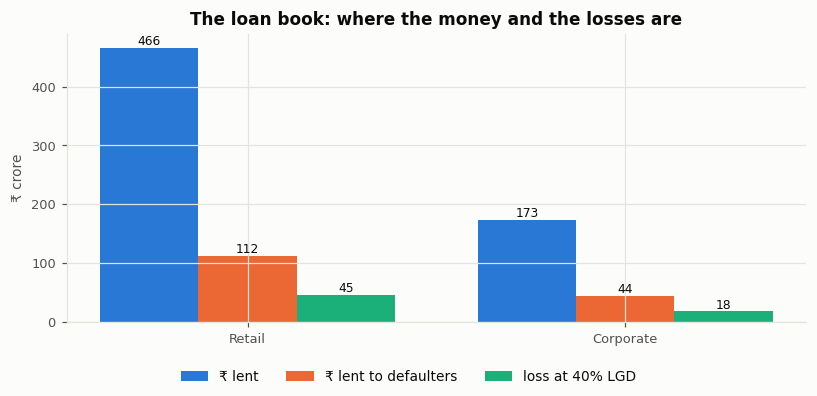

In [4]:
def book_view(t: pd.DataFrame) -> pd.Series:
    """Loan count, ₹ lent, default rates (by count and by money), ₹ in defaulted loans, loss at 40%."""
    lent = t.Loan_Amount.sum()
    to_defaulters = t.Loan_Amount[t.Default_Flag == 1].sum()
    return pd.Series({
        "Loans": len(t),
        "₹ lent (crore)": lent / CRORE,
        "Default rate (count)": t.Default_Flag.mean(),
        "Default rate (money)": to_defaulters / lent,
        "₹ lent to defaulters (crore)": to_defaulters / CRORE,
        "Loss at 40% LGD (crore)": LGD * to_defaulters / CRORE,
        "Average loan (₹ lakh)": t.Loan_Amount.mean() / LAKH,
        "Average interest rate (%)": t.Interest_Rate.mean(),
    })


board = pd.concat({k: book_view(g) for k, g in loans.groupby("Customer_Type", observed=True)}, axis=1)
board["Whole book"] = book_view(loans)
display(board.style.format("{:,.2f}").format("{:.1%}", subset=pd.IndexSlice[["Default rate (count)",
                                                                           "Default rate (money)"], :])
             .format("{:,.0f}", subset=pd.IndexSlice[["Loans"], :]))
save_table(board.T.reset_index(names="Segment"), "loan_book_board_view")

# Does the default rate by money exceed the rate by count? Check with average loan size by outcome.
size = loans.groupby("Default_Flag").Loan_Amount.mean() / LAKH
print(f"Average loan: repaid ₹{size[0]:.1f} lakh, defaulted ₹{size[1]:.1f} lakh "
      f"(defaulted loans are {size[1] / size[0] - 1:+.0%} larger on average)")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
segs = ["Retail", "Corporate"]
lent = [board.loc["₹ lent (crore)", s] for s in segs]
bad = [board.loc["₹ lent to defaulters (crore)", s] for s in segs]
loss = [board.loc["Loss at 40% LGD (crore)", s] for s in segs]
x = np.arange(len(segs)); w = 0.26
for i, (vals, lab, col) in enumerate([(lent, "₹ lent", BLUE), (bad, "₹ lent to defaulters", ORANGE),
                                      (loss, "loss at 40% LGD", AQUA)]):
    bars = ax.bar(x + (i - 1) * w, vals, w, label=lab, color=col)
    ax.bar_label(bars, fmt="%.0f", fontsize=8)
ax.set_xticks(x, segs); ax.set_ylabel("₹ crore")
ax.set_title("The loan book: where the money and the losses are")
fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.08, 1, 1))
save_chart(fig, "02_loan_book_board_view")
plt.show()

### 1d. Collateral cover and loan term

**Collateral cover** = Collateral_Value ÷ Loan_Amount, i.e. how many rupees of pledged asset stand behind each rupee lent.
- Cover **below 1** means the loan is larger than the asset (**under-collateralised**). If the borrower defaults, selling the asset cannot repay the loan in full.
- Collateral affects **how much is lost** after a default (LGD), which is a Task 3 matter. Here we check whether it also predicts **whether** a borrower defaults.

**Loan term:** does default rise with the length of the loan? If Default_Flag counted defaults over a loan's whole life, 7-year loans would default far more often than 1-year loans. The answer guides how Task 3 compares interest with expected loss (decision M2-05).

,Loans,Default_rate,Lent_crore
Collateral cover (fifths),,,
0.50–0.79,1000,17.6%,128.9
0.79–1.09,1000,19.4%,126.5
1.09–1.41,1000,21.9%,130.5
1.41–1.71,1000,20.3%,122.8
1.71–2.00,1000,20.5%,130.9


Under-collateralised loans (cover < 1): 1,665 of 5,000 (33%), ₹212.7 crore lent; their default rate 18.5% vs 20.7% for the rest


Loan_Term_Months,12,24,36,48,60,72,84
Loans,733,703,716,721,698,734,695
Default_rate,19.1%,19.2%,20.8%,20.4%,19.9%,20.4%,19.7%


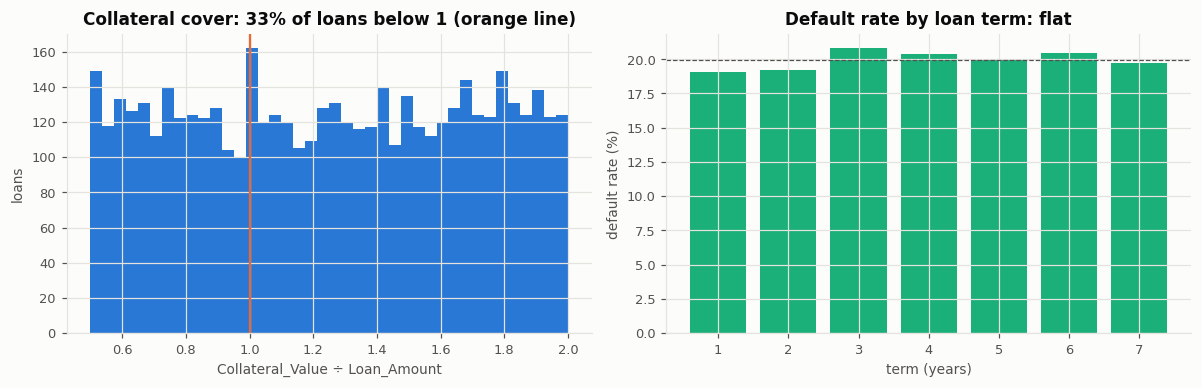

In [5]:
cover = loans.Collateral_Value / loans.Loan_Amount
under = cover < 1
cover_tbl = (pd.DataFrame({"cover": pd.qcut(cover, 5), "y": y_all, "amt": loans.Loan_Amount})
               .groupby("cover", observed=True)
               .agg(Loans=("y", "size"), Default_rate=("y", "mean"), Lent_crore=("amt", lambda a: a.sum() / CRORE)))
cover_tbl.index = [f"{iv.left:.2f}–{iv.right:.2f}" for iv in cover_tbl.index]
display(cover_tbl.rename_axis("Collateral cover (fifths)").style.format({"Default_rate": "{:.1%}",
                                                                        "Lent_crore": "{:,.1f}"}))
print(f"Under-collateralised loans (cover < 1): {under.sum():,} of {len(loans):,} ({under.mean():.0%}), "
      f"₹{loans.Loan_Amount[under].sum() / CRORE:,.1f} crore lent; their default rate {y_all[under].mean():.1%} "
      f"vs {y_all[~under].mean():.1%} for the rest")

term_tbl = (loans.groupby("Loan_Term_Months")
                 .agg(Loans=("Default_Flag", "size"), Default_rate=("Default_Flag", "mean")))
display(term_tbl.T.style.format("{:.1%}", subset=pd.IndexSlice[["Default_rate"], :])
                .format("{:,.0f}", subset=pd.IndexSlice[["Loans"], :]))
save_table(cover_tbl.reset_index(names="Collateral cover"), "collateral_cover")
save_table(term_tbl.reset_index(), "default_by_term")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.hist(cover, bins=40, color=BLUE)
a1.axvline(1, color=ORANGE, lw=1.5)
a1.set_title(f"Collateral cover: {under.mean():.0%} of loans below 1 (orange line)")
a1.set_xlabel("Collateral_Value ÷ Loan_Amount"); a1.set_ylabel("loans")
a2.bar(term_tbl.index // 12, term_tbl.Default_rate * 100, color=AQUA)
a2.axhline(y_all.mean() * 100, color=INK_2, ls="--", lw=0.8)
a2.set_title("Default rate by loan term: flat"); a2.set_xlabel("term (years)"); a2.set_ylabel("default rate (%)")
fig.tight_layout()
save_chart(fig, "03_collateral_and_term")
plt.show()

## 2. The 15 inputs, the leakage check, and why Interest_Rate is not an input

**Inputs are fixed here, before any model is trained, and are not changed after seeing results** (decision M2-11).

**Given in the data (11):**
- Annual_Income, Employment_Length, Debt_to_Income, Credit_Score, Existing_Loan, Loan_Amount, Loan_Term_Months, Collateral_Value, Past_Default, Sector_Risk: these are on the brief's list;
- **Customer_Type** (Retail / Corporate): not on the brief's list, but in the data, and lenders assess the two segments differently.

**Derived (4): standard lending ratios a credit officer looks at.** Each uses only the loan's own numbers:

```text
Loan_to_Value        = Loan_Amount ÷ Collateral_Value                         above 1 = loan larger than the asset
Loan_to_Income       = Loan_Amount ÷ Annual_Income                            loan size against yearly income
Total_Debt_to_Income = (Existing_Loan + Loan_Amount) ÷ Annual_Income          all debt after this loan
Principal_to_Income  = (Loan_Amount ÷ (Loan_Term_Months ÷ 12)) ÷ Annual_Income
                       share of yearly income needed just to repay the principal
```

A monthly-instalment (EMI) ratio was considered and dropped. An EMI needs the interest rate, which would bring the rate back in through the side door.

**Leakage check.** Leakage means a model sees information it would not have at the time of the decision.
- All 15 inputs are known **when the application is made**.
- Past_Default is the borrower's history **before** this loan.
- Default_Flag is the outcome and is never an input.

**Why Interest_Rate is left out of the challengers:**

| Reason | Explanation |
| --- | --- |
| Circular | The bank sets the rate from its own view of the borrower's risk. A model using it would partly learn the bank's opinion back |
| Finds mispricing | Without the rate, the model can spot loans the bank priced as risky that are actually safe (lend more, at a fair price) and the reverse (fewer defaults). Step 7 measures this |
| Works before pricing | The model can score an applicant before a rate is quoted, as real lending works |
| Possible leakage | If rates were ever raised after a borrower struggled (penalty pricing), the rate would carry information from after the loan started. The data can't rule this out |

The rate is still used:
- as the **champion** (step 4);
- in Task 3 as the **income** a loan earns.

The check below shows how much of the rate the fundamentals already explain.

In [6]:
CAT_INPUTS = ["Customer_Type"]                                  # one label input
NUM_INPUTS = [c for c in MODEL_INPUTS if c not in CAT_INPUTS]   # 14 number inputs

inputs_tbl = pd.DataFrame({
    "Input": MODEL_INPUTS,
    "Source": ["Given (brief's list)" if c in GIVEN_INPUTS and c != "Customer_Type"
               else "Given (in the data)" if c == "Customer_Type" else "Derived" for c in MODEL_INPUTS],
    "Formula / meaning": [RATIO_FORMULAS.get(c, "as given") for c in MODEL_INPUTS],
    "Known at application?": "Yes",
})
display(inputs_tbl)
save_table(inputs_tbl, "model_inputs")

# How much of the bank's interest rate do the fundamentals explain?
# R² = share of the rate's variation explained by a straight-line fit on the 15 inputs (descriptive only).
X_fund = pd.get_dummies(loans[MODEL_INPUTS], drop_first=True, dtype=float)
r2 = LinearRegression().fit(X_fund, loans.Interest_Rate).score(X_fund, loans.Interest_Rate)
print(f"Share of Interest_Rate explained by the 15 fundamentals (R²): {r2:.1%}")
print("→ the bank's price already reflects most of the fundamentals. A challenger must find what is left over.")

,Input,Source,Formula / meaning,Known at application?
0,Annual_Income,Given (brief's list),as given,Yes
1,Employment_Length,Given (brief's list),as given,Yes
2,Debt_to_Income,Given (brief's list),as given,Yes
3,Credit_Score,Given (brief's list),as given,Yes
4,Existing_Loan,Given (brief's list),as given,Yes
5,Loan_Amount,Given (brief's list),as given,Yes
6,Loan_Term_Months,Given (brief's list),as given,Yes
7,Collateral_Value,Given (brief's list),as given,Yes
8,Past_Default,Given (brief's list),as given,Yes
9,Sector_Risk,Given (brief's list),as given,Yes


Share of Interest_Rate explained by the 15 fundamentals (R²): 72.2%
→ the bank's price already reflects most of the fundamentals. A challenger must find what is left over.


## 3. Train / test split: build on 4,000 loans, keep 1,000 for the final exam

The decision (M2-07):
- **80% training set (4,000 loans):** all model building, tuning and comparison happen here, through cross-validation (step 5).
- **20% test set (1,000 loans):** locked away. It is used **once**, at the end (step 8), to score the chosen challenger and the champion on loans no model has seen. It is the closest thing to "next year's applicants".

**Stratified on Default_Flag × Customer_Type:** both sets keep the same default rate (19.9%) **and** the same Retail/Corporate mix, so the test result isn't skewed by an odd segment mix.

Random rather than by time, because the file has no dates.

In [7]:
# Stratification key: the 4 combinations of outcome × customer type (e.g. "1_Retail").
strata = loans.Default_Flag.astype(str) + "_" + loans.Customer_Type.astype(str)

train_idx, test_idx = train_test_split(loans.index, test_size=0.20, stratify=strata, random_state=SEED)
train = loans.loc[train_idx].reset_index(drop=True)
test = loans.loc[test_idx].reset_index(drop=True)
strata_train = strata.loc[train_idx].reset_index(drop=True)


def set_summary(t: pd.DataFrame) -> pd.Series:
    """Size, defaults, default rate, Retail share and ₹ lent for one set."""
    return pd.Series({"Loans": len(t), "Defaults": int(t.Default_Flag.sum()),
                      "Default rate": t.Default_Flag.mean(),
                      "Retail share": (t.Customer_Type == "Retail").mean(),
                      "₹ lent (crore)": t.Loan_Amount.sum() / CRORE})


split_tbl = pd.DataFrame({"Training set": set_summary(train), "Test set": set_summary(test),
                          "Whole book": set_summary(loans)})
display(split_tbl.style.format("{:,.3f}"))
save_table(split_tbl.T.reset_index(names="Set"), "train_test_split_summary")

# Model inputs and target for each set.
X_train, y_train = train[MODEL_INPUTS + ["Interest_Rate"]], train.Default_Flag.to_numpy()
X_test, y_test = test[MODEL_INPUTS + ["Interest_Rate"]], test.Default_Flag.to_numpy()
# Interest_Rate travels with X only so the champion can use it; challengers never see it (step 5).

,Training set,Test set,Whole book
Loans,"4,000.000","1,000.000","5,000.000"
Defaults,798.000,199.000,997.000
Default rate,0.200,0.199,0.199
Retail share,0.739,0.739,0.739
₹ lent (crore),511.802,127.851,639.653


## 4. Champion and reference

| Role | Model | What it represents |
| --- | --- | --- |
| **Champion** | Interest_Rate alone | The bank's own risk view: the higher the rate it charged, the riskier it judged the borrower |
| Reference | Credit_Score alone | The credit bureau's view of the borrower: what an outside score already knows |

**From a score to a PD.** A rate of 12% is not a probability. To compare it fairly with the challengers' PDs (e.g. with the Brier score), each single input is turned into a PD by a **one-input logistic regression**, fitted inside every training round:

```text
PD = 1 ÷ (1 + e^−(b0 + b1 × input))
b0, b1 learned from the training loans: how default odds change as the rate (or score) changes
```

This keeps the **order** of the input (higher rate → higher PD), so ranking measures like ROC-AUC are the same as using the raw rate. It only converts the rate into a probability scale.

In [8]:
def make_preparation(numbers: list, labels: list, scale: bool) -> ColumnTransformer:
    """Preparation step for one model; it learns nothing until the Pipeline is fitted.

    numbers → standardised (z = (x − mean) ÷ standard deviation) if scale=True, else passed through.
              Logistic models need scaling so their penalty treats every input fairly;
              trees only ask "is x above a threshold?", which scaling does not change.
    labels  → one 0/1 column per category (one-hot encoding), e.g. Customer_Type = Retail → Retail = 1.
    Any column not listed (e.g. Interest_Rate for the challengers) is DROPPED, so a model can
    only see the inputs it is given.
    """
    parts = [("num", StandardScaler() if scale else "passthrough", numbers)]
    if labels:
        parts.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False, drop="if_binary"),
                      labels))
    return ColumnTransformer(parts, remainder="drop")


def single_input_model(column: str) -> Pipeline:
    """Champion / reference: a one-input logistic regression (turns the score into a PD)."""
    return Pipeline([("prep", make_preparation([column], [], scale=True)),
                     ("model", LogisticRegression(max_iter=2000))])


CHAMPION, REFERENCE = "Champion: interest rate", "Reference: credit score"
print("Champion uses:", ["Interest_Rate"], "| Reference uses:", ["Credit_Score"])

Champion uses: ['Interest_Rate'] | Reference uses: ['Credit_Score']


## 5. The challengers: 25 rounds of cross-validation

### How every model is tested: repeated stratified 5-fold cross-validation (decision M2-07)

```text
4,000 training loans, shuffled and cut into 5 equal parts ("folds") of 800

Round 1: train on parts 2–5 (3,200 loans) → score part 1 (800 loans it never saw)
Round 2: train on parts 1, 3, 4, 5        → score part 2
...  each part is scored once
Repeat with 5 different shuffles  →  5 × 5 = 25 scores per model
```

**Why:**
- One set of 800 loans holds only about 160 defaults, so one score can move by about ±0.02 ROC-AUC on luck alone. Averaging 25 rounds gives a reliable figure and its spread.
- Every model is scored on **the same 25 sets of loans** (fixed seed), so the models can be compared round by round (paired). This removes "easy fold vs hard fold" noise.
- **Stratified** on Default_Flag × Customer_Type, like the split.
- **No leakage:** everything that learns from data (scaling, one-hot columns, tuned settings) is learned on the training part of each round only, inside a Pipeline.
- **Out-of-fold PD:** in each repeat, every training loan is scored once by a model that didn't see it. Averaging its 5 scores gives an honest PD for steps 7 and 9.

### The five challengers (decision M2-13): all use the same 15 inputs, none uses Interest_Rate

| Model | What it is, in plain words | Settings |
| --- | --- | --- |
| Logistic regression | Adds up weighted inputs and turns the total into a probability: PD = 1 ÷ (1 + e^−(b0 + b1·x1 + … + bk·xk)). The industry-standard credit scorecard | Small ridge penalty (scikit-learn default, C = 1) |
| Lasso logistic regression | The same, but the penalty λ × Σ\|b\| pushes weak weights to exactly 0, so the scorecard keeps only inputs that help | λ chosen by an inner 5-fold CV inside each round (10 values, best Brier) |
| Decision tree | A flowchart of yes/no rules, e.g. "Past_Default = 1 and Debt_to_Income > 0.5 → high risk" | Depth chosen by inner 5-fold CV (2–6); at least 50 loans per final box |
| Random forest | 300 trees, each on a random resample of loans and inputs, averaged | Depth ≤ 8; at least 20 loans per final box |
| Gradient boosting (LightGBM) | 300 small trees built one after another, each correcting the errors left by the previous ones | Tree size chosen by inner 5-fold CV (4, 8 or 16 leaves); learning rate 0.05 |

The settings are fixed here before any results. The tuned ones are chosen **inside** each round, on that round's training loans only (nested cross-validation).

**Not rebalanced** (decision M2-12): every loan counts once. Step 5b shows why.

In [9]:
INNER = StratifiedKFold(5, shuffle=True, random_state=SEED)       # inner CV used for tuning inside each round


def make_challengers() -> dict:
    """The five challengers, each a Pipeline (preparation → model) on the 15 inputs.

    The order goes from simplest to most complex; step 6 uses it to prefer the simpler
    model when two are equally good (decision M2-13).
    """
    linear_prep = lambda: make_preparation(NUM_INPUTS, CAT_INPUTS, scale=True)
    tree_prep = lambda: make_preparation(NUM_INPUTS, CAT_INPUTS, scale=False)
    return {
        # Lasso: L1 penalty; LogisticRegressionCV runs the inner CV to choose among 10 penalty values.
        # solver="liblinear" supports the L1 penalty; scoring by Brier score (probability quality).
        "Lasso": Pipeline([("prep", linear_prep()),
                           ("model", LogisticRegressionCV(Cs=10, penalty="l1", solver="liblinear", cv=INNER,
                                                          scoring="neg_brier_score", max_iter=5000,
                                                          random_state=SEED))]),   # liblinear shuffles internally: fix its seed
        # Plain logistic regression with scikit-learn's default small ridge (L2) penalty, C = 1.
        "Logistic regression": Pipeline([("prep", linear_prep()),
                                         ("model", LogisticRegression(C=1.0, max_iter=5000))]),
        # Decision tree: depth tuned 2–6 by inner CV (Brier); at least 50 loans per final box.
        "Decision tree": Pipeline([("prep", tree_prep()),
                                   ("model", GridSearchCV(
                                       DecisionTreeClassifier(min_samples_leaf=50, random_state=SEED),
                                       {"max_depth": [2, 3, 4, 5, 6]}, cv=INNER, scoring="neg_brier_score"))]),
        # Random forest: 300 trees, depth ≤ 8, at least 20 loans per final box; n_jobs=1 keeps memory low.
        "Random forest": Pipeline([("prep", tree_prep()),
                                   ("model", RandomForestClassifier(n_estimators=300, max_depth=8,
                                                                    min_samples_leaf=20, random_state=SEED,
                                                                    n_jobs=1))]),
        # LightGBM: 300 boosted trees, learning rate 0.05, 80% of loans and inputs per tree;
        # tree size (num_leaves) tuned by inner CV; at least 50 loans per leaf.
        "LightGBM": Pipeline([("prep", tree_prep()),
                              ("model", GridSearchCV(
                                  LGBMClassifier(n_estimators=300, learning_rate=0.05, min_child_samples=50,
                                                 subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                                 random_state=SEED, n_jobs=1, verbose=-1),
                                  {"num_leaves": [4, 8, 16]}, cv=INNER, scoring="neg_brier_score"))]),
    }


CHALLENGERS = list(make_challengers())
COMPLEXITY = {name: i for i, name in enumerate(CHALLENGERS)}     # 0 = simplest
print("Challengers (simplest → most complex):", ", ".join(CHALLENGERS))

Challengers (simplest → most complex): Lasso, Logistic regression, Decision tree, Random forest, LightGBM


### The measures (formulas)

A **default is the "positive" class**, because catching defaulters is the point.

| Measure | Formula / meaning | Better | Why the Board cares |
| --- | --- | --- | --- |
| **Brier score** (primary) | average of (PD − actual 0/1)². A PD of 0.30 on a loan that defaults scores (0.30 − 1)² = 0.49; on one that repays, 0.30² = 0.09 | Lower | Task 3 multiplies PD by money, so PDs must be right, not just well ordered |
| ROC-AUC | The chance that a randomly picked defaulter gets a higher PD than a randomly picked repayer. 0.5 = coin toss, 1 = perfect | Higher | Ranking quality: does the model put risky borrowers above safe ones? |
| Gini | 2 × ROC-AUC − 1, the form banks usually report | Higher | Same as ROC-AUC, bank convention |
| KS | The largest gap between the share of defaulters and the share of repayers scored below any PD line | Higher | A standard bank scorecard measure: how well one cut-off separates good and bad |
| Log loss | average of −[y × ln(PD) + (1 − y) × ln(1 − PD)]; punishes confident wrong PDs heavily | Lower | Another view of probability quality |
| Average PD vs actual rate | mean PD against the share that really defaulted | Close | Is the overall PD level right? |
| Calibration slope | b in: logit(actual) ≈ a + b × logit(PD). 1 = right; below 1 = PDs too extreme | Close to 1 | PDs neither too bold nor too timid |
| Precision / recall / F1 at 30% PD | Flag loans with PD > 30%. **Precision** = flagged loans that really defaulted ÷ flagged. **Recall** = defaulters flagged ÷ all defaulters. **F1** = 2 × P × R ÷ (P + R) | Higher | Above 30% PD, the expected loss (≥ 12% of the loan a year) uses up the interest of even the riskiest loans |

**Accuracy is not used.** 80% of loans don't default, so a model that says "nobody defaults" would score 80% while being useless.

In [10]:
FLAG_AT = 0.30                             # PD line for precision / recall / F1


def ks_stat(y, p) -> float:
    """KS = largest gap between the cumulative shares of defaulters and repayers along the PD scale."""
    fpr, tpr, _ = roc_curve(y, p)          # tpr = defaulters above a line, fpr = repayers above it
    return float(np.max(tpr - fpr))


def calibration_slope(y, p) -> float:
    """Fit logit(actual) ≈ a + b × logit(PD); return b (1 = well calibrated)."""
    p = np.clip(p, 1e-6, 1 - 1e-6)
    z = np.log(p / (1 - p)).reshape(-1, 1)
    return float(LogisticRegression(C=1e6, max_iter=1000).fit(z, y).coef_[0, 0])


def measures(y, p) -> dict:
    """All the agreed measures for one set of predictions."""
    flag = p > FLAG_AT
    auc = roc_auc_score(y, p)
    return {"Brier": brier_score_loss(y, p), "ROC_AUC": auc, "Gini": 2 * auc - 1, "KS": ks_stat(y, p),
            "Log_loss": log_loss(y, p), "Average_PD": float(np.mean(p)), "Actual_rate": float(np.mean(y)),
            "Calibration_slope": calibration_slope(y, p),
            "Precision": precision_score(y, flag, zero_division=0), "Recall": recall_score(y, flag),
            "F1": f1_score(y, flag, zero_division=0)}


print("Measures:", ", ".join(measures(np.array([0, 1, 0, 1]), np.array([.1, .6, .2, .4]))))

Measures: Brier, ROC_AUC, Gini, KS, Log_loss, Average_PD, Actual_rate, Calibration_slope, Precision, Recall, F1


### Run the comparison

Every model goes through the same 25 rounds. The training score of each round is kept too, for the overfitting check (step 5c).

In [11]:
N_SPLITS, N_REPEATS = 5, 5
cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
SPLITS = list(cv.split(X_train, strata_train))       # stratified on outcome × customer type; reused by every model


def run_cv(make_model, name: str, sample_weight_fn=None):
    """Train and score one model in all 25 rounds.

    make_model: a function returning a fresh, unfitted Pipeline (so no round sees another's fit).
    sample_weight_fn: only for the rebalancing comparison in step 5b.
    Returns (per-round measures as a DataFrame, out-of-fold PD per training loan).
    """
    rows, oof_sum = [], np.zeros(len(y_train))
    for r, (tr, te) in enumerate(SPLITS, start=1):
        model = make_model()
        fit_kw = {}
        if sample_weight_fn is not None:
            fit_kw["model__sample_weight"] = sample_weight_fn(y_train[tr])
        model.fit(X_train.iloc[tr], y_train[tr], **fit_kw)
        p_test = model.predict_proba(X_train.iloc[te])[:, 1]       # loans this round never saw
        p_fit = model.predict_proba(X_train.iloc[tr])[:, 1]        # loans it learned from (overfitting check)
        oof_sum[te] += p_test
        m = measures(y_train[te], p_test)
        m.update({"Model": name, "Round": r, "Train_ROC_AUC": roc_auc_score(y_train[tr], p_fit),
                  "Train_Brier": brier_score_loss(y_train[tr], p_fit)})
        rows.append(m)
    return pd.DataFrame(rows), oof_sum / N_REPEATS                  # each loan scored once per repeat


ALL_MODELS = {CHAMPION: lambda: single_input_model("Interest_Rate"),
              REFERENCE: lambda: single_input_model("Credit_Score"),
              **{name: (lambda n=name: make_challengers()[n]) for name in CHALLENGERS}}

results, OOF = [], {}
for name, factory in ALL_MODELS.items():
    t0 = time.time()
    rounds, OOF[name] = run_cv(factory, name)
    results.append(rounds)
    print(f"{name:<26} done in {time.time() - t0:5.1f}s | Brier {rounds.Brier.mean():.4f} | "
          f"ROC-AUC {rounds.ROC_AUC.mean():.3f}")
cv_rounds = pd.concat(results, ignore_index=True)
save_table(cv_rounds, "cv_rounds")

Champion: interest rate    done in   0.8s | Brier 0.1444 | ROC-AUC 0.702


Reference: credit score    done in   0.8s | Brier 0.1542 | ROC-AUC 0.632


Lasso                      done in  16.6s | Brier 0.1411 | ROC-AUC 0.731


Logistic regression        done in   1.2s | Brier 0.1413 | ROC-AUC 0.730


Decision tree              done in  13.6s | Brier 0.1494 | ROC-AUC 0.679


Random forest              done in  52.5s | Brier 0.1442 | ROC-AUC 0.718


LightGBM                   done in  67.3s | Brier 0.1445 | ROC-AUC 0.716


,Brier,ROC_AUC,Gini,KS,Log_loss,Average_PD,Actual_rate,Calibration_slope,Precision,Recall,F1
Model,,,,,,,,,,,
Champion: interest rate,0.1444,0.702,0.404,0.322,0.456,0.199,0.200,1.008,0.446,0.366,0.401
Reference: credit score,0.1542,0.632,0.264,0.213,0.483,0.200,0.200,1.018,0.370,0.190,0.251
Lasso,0.1411,0.731,0.462,0.363,0.445,0.202,0.200,1.032,0.432,0.436,0.433
Logistic regression,0.1413,0.730,0.460,0.363,0.445,0.200,0.200,0.965,0.432,0.437,0.434
Decision tree,0.1494,0.679,0.359,0.289,0.469,0.199,0.200,0.749,0.395,0.380,0.382
Random forest,0.1442,0.718,0.435,0.344,0.453,0.199,0.200,1.271,0.423,0.381,0.401
LightGBM,0.1445,0.716,0.431,0.341,0.454,0.198,0.200,0.842,0.406,0.420,0.412


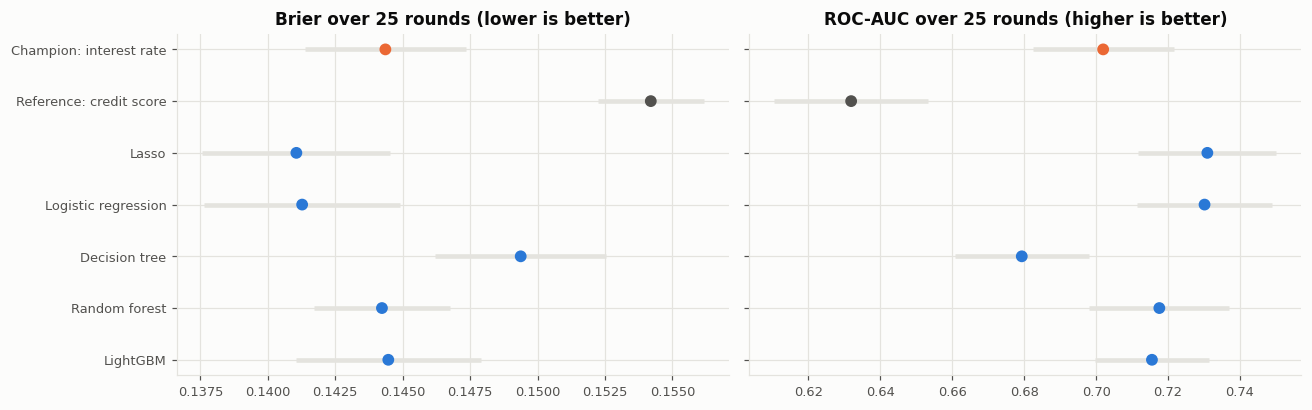

In [12]:
# Summary: mean over the 25 rounds, and the standard deviation (how much a score depends on luck).
SHOW = ["Brier", "ROC_AUC", "Gini", "KS", "Log_loss", "Average_PD", "Actual_rate", "Calibration_slope",
        "Precision", "Recall", "F1"]
MODEL_ORDER = [CHAMPION, REFERENCE] + CHALLENGERS
mean_tbl = cv_rounds.groupby("Model")[SHOW].mean().loc[MODEL_ORDER]
std_tbl = cv_rounds.groupby("Model")[SHOW].std().loc[MODEL_ORDER]
cv_summary = mean_tbl.copy()
cv_summary.columns = [c + " (mean)" for c in SHOW]
for c in ["Brier", "ROC_AUC", "KS"]:
    cv_summary[c + " (std)"] = std_tbl[c]
display(mean_tbl.style.format("{:.3f}").format("{:.4f}", subset=["Brier"])
                .highlight_min(subset=["Brier", "Log_loss"], color="#d6ecdf")
                .highlight_max(subset=["ROC_AUC", "KS"], color="#d6ecdf"))
save_table(cv_summary.reset_index(), "cv_summary")

# Chart: Brier (lower is better) and ROC-AUC (higher is better), mean ± 1 standard deviation.
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col, better in [(axes[0], "Brier", "lower is better"), (axes[1], "ROC_AUC", "higher is better")]:
    ypos = np.arange(len(MODEL_ORDER))[::-1]
    colours = [ORANGE if m == CHAMPION else INK_2 if m == REFERENCE else BLUE for m in MODEL_ORDER]
    ax.errorbar(mean_tbl[col], ypos, xerr=std_tbl[col], fmt="none", ecolor=GRID, elinewidth=3)
    ax.scatter(mean_tbl[col], ypos, c=colours, s=45, zorder=3)
    ax.set_yticks(ypos, MODEL_ORDER)
    ax.set_title(f"{col.replace('_', '-')} over 25 rounds ({better})")
axes[1].set_yticklabels([])
fig.tight_layout()
save_chart(fig, "04_cv_comparison")
plt.show()

## 5b. Why we don't rebalance the defaults (evidence for decision M2-12)

Only 19.9% of loans default. A common ML habit is **class weights**: each default counts about 4× as much during training, so the model "pays more attention" to the rare class.

Here we run plain logistic regression both ways, in the same 25 rounds. The ₹ column turns the average PD into money, as Task 3 will:

```text
Expected loss (₹) = Σ over loans of  PD × 40% × Loan_Amount
```

In [13]:
from sklearn.utils.class_weight import compute_sample_weight      # "balanced" = each class counts equally

bal_rounds, bal_oof = run_cv(lambda: make_challengers()["Logistic regression"], "Logistic (class-weighted)",
                             sample_weight_fn=lambda yy: compute_sample_weight("balanced", yy))
plain = cv_rounds[cv_rounds.Model == "Logistic regression"]
amt_train = train.Loan_Amount.to_numpy()
actual_loss = LGD * (amt_train * y_train).sum() / CRORE           # what really happened, at 40% LGD


def weight_row(label, rounds, oof):
    return {"Training": label, "ROC-AUC": rounds.ROC_AUC.mean(), "Brier": rounds.Brier.mean(),
            "Average PD": oof.mean(), "Expected loss (₹ crore)": (oof * LGD * amt_train).sum() / CRORE}


balance_tbl = pd.DataFrame([weight_row("As the data is (chosen)", plain, OOF["Logistic regression"]),
                            weight_row("Class-weighted", bal_rounds, bal_oof)])
balance_tbl.loc[len(balance_tbl)] = {"Training": "What actually happened", "ROC-AUC": np.nan, "Brier": np.nan,
                                     "Average PD": y_train.mean(), "Expected loss (₹ crore)": actual_loss}
display(balance_tbl.style.format({"ROC-AUC": "{:.3f}", "Brier": "{:.4f}", "Average PD": "{:.1%}",
                                  "Expected loss (₹ crore)": "{:,.1f}"}, na_rep="—"))
save_table(balance_tbl, "rebalancing_evidence")

,Training,ROC-AUC,Brier,Average PD,Expected loss (₹ crore)
0,As the data is (chosen),0.730,0.1413,20.0%,50.1
1,Class-weighted,0.730,0.2089,44.9%,105.2
2,What actually happened,—,—,20.0%,50.0


## 5c. Overfitting check: training loans vs unseen loans

**Overfitting** = a model memorises its training loans instead of learning patterns that carry over. It shows as a **large gap** between its score on the loans it learned from and on the loans it never saw.

```text
Gap = ROC-AUC on the round's training loans − ROC-AUC on its unseen loans
```

A small drop is normal: every model fits the loans it learned from a little better. What matters is how big the drop is.

**The limit: an average gap above 0.05 = overfitting** (decision M2-13).
- **Where it comes from:** a judgement set before the results. There is no single industry standard; banks use various rules, often a drop in Gini between development and validation data.
- **Why 0.05 is a fair line:** from round to round, a model's unseen ROC-AUC moves by about 0.02 just from which loans land in the fold. So a single round's gap can reach about ±0.05 even for a model that can't memorise (the one-input champion). **Averaged over 25 rounds**, an honest model's gap is close to 0, so an average gap above 0.05 is far beyond luck.
- **Check:** the code below shows the spread of the gap in single rounds, and which models other limits would rule out. Step 6 shows that the overfitting models lose on unseen loans anyway, so the choice doesn't depend on the exact limit.

,Train_ROC_AUC,CV_ROC_AUC,Train_Brier,CV_Brier,ROC-AUC gap,Overfits (gap > 0.05)?
Model,,,,,,
Champion: interest rate,0.702,0.702,0.1443,0.1444,-0.000,No
Reference: credit score,0.632,0.632,0.1541,0.1542,-0.000,No
Lasso,0.737,0.731,0.1398,0.1411,0.006,No
Logistic regression,0.737,0.730,0.1397,0.1413,0.007,No
Decision tree,0.729,0.679,0.1387,0.1494,0.049,No
Random forest,0.851,0.718,0.1249,0.1442,0.133,Yes
LightGBM,0.825,0.716,0.1220,0.1445,0.109,Yes


,Average gap,Smallest round,Largest round
Model,,,
Champion: interest rate,-0.000,-0.055,+0.038
Reference: credit score,-0.000,-0.060,+0.064
Lasso,+0.006,-0.053,+0.051
Logistic regression,+0.007,-0.052,+0.050
Decision tree,+0.049,+0.008,+0.080
Random forest,+0.133,+0.094,+0.168
LightGBM,+0.109,+0.074,+0.146


Limit 0.03 would rule out: ['Decision tree', 'Random forest', 'LightGBM']
Limit 0.05 would rule out: ['Random forest', 'LightGBM']
Limit 0.08 would rule out: ['Random forest', 'LightGBM']
Limit 0.10 would rule out: ['Random forest', 'LightGBM']
Limit 0.12 would rule out: ['Random forest']


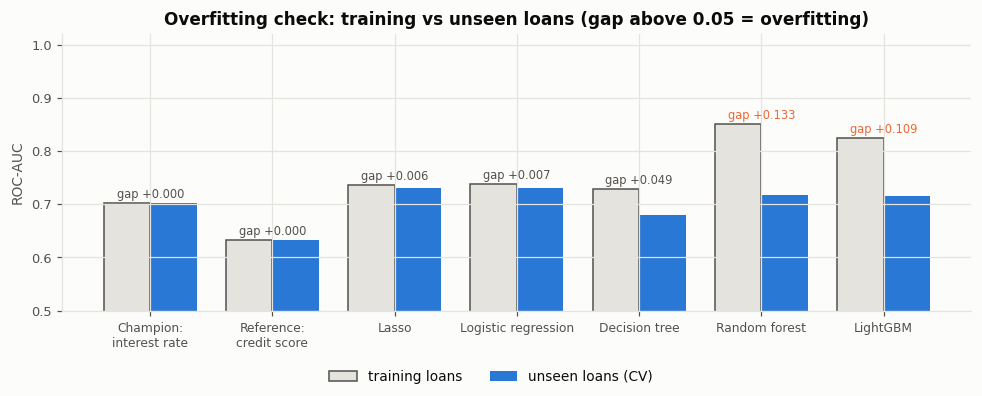

In [14]:
GAP_LIMIT = 0.05
over = (cv_rounds.groupby("Model")[["Train_ROC_AUC", "ROC_AUC", "Train_Brier", "Brier"]].mean()
                 .loc[MODEL_ORDER]
                 .rename(columns={"ROC_AUC": "CV_ROC_AUC", "Brier": "CV_Brier"}))
over["ROC-AUC gap"] = over.Train_ROC_AUC - over.CV_ROC_AUC
over["Overfits (gap > 0.05)?"] = np.where(over["ROC-AUC gap"] > GAP_LIMIT, "Yes", "No")
display(over.style.format("{:.3f}", subset=["Train_ROC_AUC", "CV_ROC_AUC", "ROC-AUC gap"])
                  .format("{:.4f}", subset=["Train_Brier", "CV_Brier"]))
save_table(over.reset_index(), "overfitting_check")

# Spread of the gap across the 25 rounds, and which models each candidate limit would rule out.
gap_rounds = cv_rounds.assign(Gap=cv_rounds.Train_ROC_AUC - cv_rounds.ROC_AUC)
display(gap_rounds.groupby("Model").Gap.agg(["mean", "min", "max"]).loc[MODEL_ORDER]
                  .rename(columns={"mean": "Average gap", "min": "Smallest round", "max": "Largest round"})
                  .style.format("{:+.3f}"))
for limit in [0.03, 0.05, 0.08, 0.10, 0.12]:
    print(f"Limit {limit:.2f} would rule out: {[m for m in CHALLENGERS if over.loc[m, 'ROC-AUC gap'] > limit] or 'none'}")

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(MODEL_ORDER)); w = 0.38
ax.bar(x - w / 2, over.Train_ROC_AUC, w, label="training loans", color=GRID, edgecolor=INK_2)
ax.bar(x + w / 2, over.CV_ROC_AUC, w, label="unseen loans (CV)", color=BLUE)
for i, g in enumerate(over["ROC-AUC gap"]):
    g = 0.0 if abs(g) < 0.0005 else g                  # show 0.000 rather than -0.000
    ax.text(i, max(over.Train_ROC_AUC.iloc[i], over.CV_ROC_AUC.iloc[i]) + 0.01, f"gap {g:+.3f}",
            ha="center", fontsize=7.5, color=ORANGE if g > GAP_LIMIT else INK_2)
ax.set_xticks(x, [m.replace(": ", ":\n") for m in MODEL_ORDER], fontsize=8)
ax.set_ylim(0.5, 1.02); ax.set_ylabel("ROC-AUC")
ax.set_title("Overfitting check: training vs unseen loans (gap above 0.05 = overfitting)")
fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0.07, 1, 1))
save_chart(fig, "05_overfitting_check")
plt.show()

## 6. Choosing the challenger: the agreed rule, step by step (decision M2-13)

The rule was fixed **before** any results:

1. **Rule out overfitting models** (gap above 0.05, step 5c).
2. **Probability quality first.** Find the remaining model with the best (lowest) mean Brier score.
3. **Simplest wins ties.** If a simpler model's Brier is within the noise of the best, keep the simpler one. "Within the noise" means the paired 95% range of the difference includes 0. Lending decisions must be explainable to the borrower and the regulator.
4. **The ₹ check** (step 7): at which approval levels does the chosen model save money compared with the champion? Reported as a finding and carried to Task 3, where the approval level is set.
5. **The test set is used once**, on the chosen challenger and the champion (step 8).

### The paired 95% range

Every model was scored on the same 25 sets of loans, so we compare them **round by round**:

```text
d     = score of model A − score of model B, in each of the 25 rounds
mean  = average of the 25 d's;   sd = their standard deviation
95% range = mean ± t × sd ÷ √25           t = 2.064 (t-distribution, 24 degrees of freedom)
```

If the whole range is on one side of 0, the difference is real, not luck.

*Caveat:* the 25 rounds reuse the same 4,000 loans, so they aren't fully independent and this range is slightly too narrow. That's why the final verdict comes from the untouched test set (step 8).

In [15]:
T_CRIT = stats.t.ppf(0.975, df=len(SPLITS) - 1)           # 2.064 for 24 degrees of freedom


def paired(model_a: str, model_b: str, col: str) -> dict:
    """Mean difference (A − B) over the 25 rounds and its 95% range."""
    a = cv_rounds[cv_rounds.Model == model_a].sort_values("Round")[col].to_numpy()
    b = cv_rounds[cv_rounds.Model == model_b].sort_values("Round")[col].to_numpy()
    d = a - b
    half = T_CRIT * d.std(ddof=1) / np.sqrt(len(d))
    return {"Mean difference": d.mean(), "Low": d.mean() - half, "High": d.mean() + half,
            "A better in rounds": int((d < 0).sum() if col in ("Brier", "Log_loss") else (d > 0).sum())}


# (a) Every challenger and the reference against the champion.
rows = []
for m in [REFERENCE] + CHALLENGERS:
    for col in ["Brier", "ROC_AUC", "KS"]:
        rows.append({"Model": m, "Measure": col, **paired(m, CHAMPION, col)})
vs_champion = pd.DataFrame(rows)
vs_champion["Verdict"] = np.select(
    [(vs_champion.Measure == "Brier") & (vs_champion.High < 0),
     (vs_champion.Measure != "Brier") & (vs_champion.Low > 0),
     (vs_champion.Measure == "Brier") & (vs_champion.Low > 0),
     (vs_champion.Measure != "Brier") & (vs_champion.High < 0)],
    ["Beats the champion", "Beats the champion", "Worse than the champion", "Worse than the champion"],
    "Within the noise")
print("Each model minus the champion (Brier: negative = better; ROC-AUC, KS: positive = better)")
display(vs_champion.style.format({"Mean difference": "{:+.4f}", "Low": "{:+.4f}", "High": "{:+.4f}"}))
save_table(vs_champion, "paired_vs_champion")

Each model minus the champion (Brier: negative = better; ROC-AUC, KS: positive = better)


,Model,Measure,Mean difference,Low,High,A better in rounds,Verdict
0,Reference: credit score,Brier,+0.0098,+0.0089,+0.0108,0,Worse than the champion
1,Reference: credit score,ROC_AUC,-0.0700,-0.0801,-0.0600,0,Worse than the champion
2,Reference: credit score,KS,-0.1089,-0.1269,-0.0909,0,Worse than the champion
3,Lasso,Brier,-0.0033,-0.0040,-0.0026,24,Beats the champion
4,Lasso,ROC_AUC,+0.0289,+0.0242,+0.0337,25,Beats the champion
5,Lasso,KS,+0.0411,+0.0297,+0.0525,22,Beats the champion
6,Logistic regression,Brier,-0.0031,-0.0038,-0.0024,24,Beats the champion
7,Logistic regression,ROC_AUC,+0.0282,+0.0235,+0.0328,25,Beats the champion
8,Logistic regression,KS,+0.0409,+0.0294,+0.0523,22,Beats the champion
9,Decision tree,Brier,+0.0050,+0.0037,+0.0063,2,Worse than the champion


In [16]:
# (b) Apply the selection rule.
eligible = [m for m in CHALLENGERS if over.loc[m, "ROC-AUC gap"] <= GAP_LIMIT]
ruled_out = [m for m in CHALLENGERS if m not in eligible]
print("Rule 1 - ruled out for overfitting:", ruled_out or "none")

best = min(eligible, key=lambda m: mean_tbl.loc[m, "Brier"])
print(f"Rule 2 - best mean Brier among the rest: {best} ({mean_tbl.loc[best, 'Brier']:.4f})")

rows = []
for m in eligible:
    if m == best:
        rows.append({"Model": m, "Brier": mean_tbl.loc[m, "Brier"], "Mean difference": 0.0, "Low": 0.0,
                     "High": 0.0, "Within the noise of the best?": "It is the best"})
        continue
    d = paired(m, best, "Brier")
    rows.append({"Model": m, "Brier": mean_tbl.loc[m, "Brier"], **{k: d[k] for k in ["Mean difference", "Low", "High"]},
                 "Within the noise of the best?": "Yes" if d["Low"] <= 0 <= d["High"] else "No"})
vs_best = pd.DataFrame(rows).drop(columns=[], errors="ignore")
display(vs_best.style.format({"Brier": "{:.4f}", "Mean difference": "{:+.4f}", "Low": "{:+.4f}", "High": "{:+.4f}"}))
save_table(vs_best, "paired_vs_best")

tied = vs_best[vs_best["Within the noise of the best?"] != "No"].Model.tolist()
CHOSEN = min(tied, key=lambda m: COMPLEXITY[m])                  # simplest among the tied
print(f"Rule 3 - models tied with the best: {tied} → simplest: {CHOSEN}")
print(f"\nChosen challenger: {CHOSEN}")

Rule 1 - ruled out for overfitting: ['Random forest', 'LightGBM']
Rule 2 - best mean Brier among the rest: Lasso (0.1411)


,Model,Brier,Mean difference,Low,High,Within the noise of the best?
0,Lasso,0.1411,+0.0000,+0.0000,+0.0000,It is the best
1,Logistic regression,0.1413,+0.0002,+0.0001,+0.0004,No
2,Decision tree,0.1494,+0.0083,+0.0069,+0.0097,No


Rule 3 - models tied with the best: ['Lasso'] → simplest: Lasso

Chosen challenger: Lasso


### Every model against the chosen one, on unseen loans only

The rejection of random forest and LightGBM does **not** rest on the overfitting check alone. Judged **only on the loans they never saw**, ignoring the training scores completely, they still lose to the chosen model on both probability accuracy (Brier) and ranking (ROC-AUC).

The training-loan Brier is shown alongside. The overfitting models have the *best* Brier on the loans they learned from, then lose on new ones: that is memorising.

In [17]:
rows = []
for m in MODEL_ORDER:
    if m == CHOSEN:
        continue
    b, a = paired(m, CHOSEN, "Brier"), paired(m, CHOSEN, "ROC_AUC")
    rows.append({"Model": m,
                 "Brier, training loans": over.loc[m, "Train_Brier"], "Brier, unseen loans": mean_tbl.loc[m, "Brier"],
                 "Brier minus chosen": b["Mean difference"], "Brier 95% low": b["Low"], "Brier 95% high": b["High"],
                 "Chosen better on Brier (rounds of 25)": 25 - b["A better in rounds"],
                 "ROC-AUC, unseen loans": mean_tbl.loc[m, "ROC_AUC"],
                 "ROC-AUC minus chosen": a["Mean difference"], "ROC-AUC 95% low": a["Low"], "ROC-AUC 95% high": a["High"],
                 "Chosen better on ROC-AUC (rounds of 25)": 25 - a["A better in rounds"]})
vs_chosen_all = pd.DataFrame(rows)
print(f"Chosen model {CHOSEN}: Brier on training loans {over.loc[CHOSEN, 'Train_Brier']:.4f}, "
      f"on unseen loans {mean_tbl.loc[CHOSEN, 'Brier']:.4f}; ROC-AUC on unseen loans {mean_tbl.loc[CHOSEN, 'ROC_AUC']:.3f}")
display(vs_chosen_all.style
        .format({c: "{:+.4f}" for c in ["Brier minus chosen", "Brier 95% low", "Brier 95% high"]})
        .format({c: "{:.4f}" for c in ["Brier, training loans", "Brier, unseen loans"]})
        .format({c: "{:+.3f}" for c in ["ROC-AUC minus chosen", "ROC-AUC 95% low", "ROC-AUC 95% high"]})
        .format({"ROC-AUC, unseen loans": "{:.3f}"}))
save_table(vs_chosen_all, "all_models_vs_chosen")

Chosen model Lasso: Brier on training loans 0.1398, on unseen loans 0.1411; ROC-AUC on unseen loans 0.731


,Model,"Brier, training loans","Brier, unseen loans",Brier minus chosen,Brier 95% low,Brier 95% high,Chosen better on Brier (rounds of 25),"ROC-AUC, unseen loans",ROC-AUC minus chosen,ROC-AUC 95% low,ROC-AUC 95% high,Chosen better on ROC-AUC (rounds of 25)
0,Champion: interest rate,0.144272,0.144359,0.003299,0.002625,0.003974,24,0.702,-0.028946,-0.033688,-0.024203,25
1,Reference: credit score,0.154085,0.154198,0.013139,0.012126,0.014152,25,0.632,-0.098960,-0.107138,-0.090781,25
2,Logistic regression,0.139715,0.141273,0.000214,0.000061,0.000367,20,0.730,-0.000782,-0.001345,-0.000218,17
3,Decision tree,0.138712,0.149375,0.008316,0.006946,0.009686,25,0.679,-0.051557,-0.059482,-0.043631,25
4,Random forest,0.124895,0.144232,0.003172,0.002395,0.003950,25,0.718,-0.013339,-0.017364,-0.009315,22
5,LightGBM,0.122003,0.144467,0.003408,0.002786,0.004030,24,0.716,-0.015391,-0.018637,-0.012144,24


## 7. The ₹ case: does the chosen challenger make the bank more money than the champion?

All on the **out-of-fold PDs** of the 4,000 training loans, so every loan is scored by a model that didn't see it. The ₹ measures (decision M2-13):

**(a) Same approval level, fewer losses.** Approve the safest X% of applicants, ranked by each model's PD, and see who would actually have defaulted:

```text
₹ lent to defaulters = Σ Loan_Amount of approved loans that defaulted
Loss at 40% LGD      = 40% × ₹ lent to defaulters
```

**(b) Same default rate, more lending.** Keep the champion's default rate at each level. How many more loans, and ₹, can the challenger approve before reaching that same rate?

**(c) Mispriced loans.** Loans the bank priced as risky that the model finds safe, and the reverse. These are the business opportunity: win good customers at a fair price, and avoid underpriced risk.

**The ₹ check (rule 4) is a finding, not a pass/fail.** Which approval level the bank uses is a Task 3 decision, so the question here is: **at which approval levels does the challenger save money?** The comparison is shown at five levels (50–90%), then **swept across every level from 30% to 100% in 1% steps** to find the turning point. A pass/fail on a few hand-picked levels would depend on which levels were picked.

In [18]:
LEVELS = [0.5, 0.6, 0.7, 0.8, 0.9]                       # approval levels: share of applicants approved
amt = amt_train


def approve_safest(pd_scores, share):
    """Indices of the safest `share` of loans by PD (ties broken by position, reproducibly)."""
    n = int(round(share * len(pd_scores)))
    return np.argsort(pd_scores, kind="stable")[:n]


rows = []
for share in LEVELS:
    for m in [CHAMPION, REFERENCE, CHOSEN]:
        idx = approve_safest(OOF[m], share)
        bad = (amt[idx] * y_train[idx]).sum()
        rows.append({"Approve": f"{share:.0%}", "Model": m, "Loans approved": len(idx),
                     "Defaults": int(y_train[idx].sum()), "Default rate": y_train[idx].mean(),
                     "₹ lent (crore)": amt[idx].sum() / CRORE, "₹ lent to defaulters (crore)": bad / CRORE,
                     "Loss at 40% (crore)": LGD * bad / CRORE})
same_approval = pd.DataFrame(rows)
display(same_approval.style.format({"Default rate": "{:.1%}", "₹ lent (crore)": "{:,.1f}",
                                    "₹ lent to defaulters (crore)": "{:,.1f}", "Loss at 40% (crore)": "{:,.2f}"}))
save_table(same_approval, "rupee_same_approval")

# Challenger minus champion at each level (negative loss difference = the challenger saves money).
piv = same_approval.pivot(index="Approve", columns="Model")
rupee_diff = pd.DataFrame({
    "Fewer defaults": piv["Defaults"][CHAMPION] - piv["Defaults"][CHOSEN],
    "Loss saved (₹ crore)": piv["Loss at 40% (crore)"][CHAMPION] - piv["Loss at 40% (crore)"][CHOSEN],
}).reindex([f"{s:.0%}" for s in LEVELS])
display(rupee_diff.style.format({"Loss saved (₹ crore)": "{:+.2f}"}))

# The sweep: every approval level from 30% to 100% in 1% steps.
SWEEP = np.round(np.arange(0.30, 1.0001, 0.01), 2)


def loss_of(model_name, share):
    """Loss at 40% LGD (₹ crore) when approving the safest `share` by this model's out-of-fold PD."""
    idx = approve_safest(OOF[model_name], share)
    return LGD * (amt[idx] * y_train[idx]).sum() / CRORE


saving = np.array([loss_of(CHAMPION, s) - loss_of(CHOSEN, s) for s in SWEEP])     # + = the challenger saves money
CROSSOVER = float(SWEEP[np.argmax(saving <= 0)])                                    # first level with no saving
ranges = [(0.30, CROSSOVER - 0.01), (CROSSOVER, 0.79), (0.80, 1.00)]
sweep_tbl = pd.DataFrame([{
    "Approval levels": f"{lo:.0%}–{hi:.0%}",
    "Levels where the challenger saves money": f"{int((saving[(SWEEP >= lo - 1e-9) & (SWEEP <= hi + 1e-9)] > 0).sum())} of "
                                               f"{int(((SWEEP >= lo - 1e-9) & (SWEEP <= hi + 1e-9)).sum())}",
    "Average saving (₹ crore)": saving[(SWEEP >= lo - 1e-9) & (SWEEP <= hi + 1e-9)].mean()} for lo, hi in ranges])
display(sweep_tbl.style.format({"Average saving (₹ crore)": "{:+.2f}"}))
save_table(pd.DataFrame({"Approval level": SWEEP, "Challenger saving (₹ crore)": saving}), "rupee_sweep")
print(f"Rule 4 - the ₹ check (finding): {CHOSEN} saves money at every approval level up to {CROSSOVER - 0.01:.0%}; "
      f"from about {CROSSOVER:.0%} upward the champion's pricing loses less. Carried to Task 3, where the approval level is set.")

,Approve,Model,Loans approved,Defaults,Default rate,₹ lent (crore),₹ lent to defaulters (crore),Loss at 40% (crore)
0,50%,Champion: interest rate,2000,225,11.2%,190.4,23.5,9.42
1,50%,Reference: credit score,2000,281,14.1%,259.9,48.7,19.48
2,50%,Lasso,2000,188,9.4%,188.2,18.3,7.33
3,60%,Champion: interest rate,2400,294,12.2%,239.3,32.5,13.01
4,60%,Reference: credit score,2400,363,15.1%,311.2,61.8,24.73
5,60%,Lasso,2400,262,10.9%,240.2,29.0,11.60
6,70%,Champion: interest rate,2800,367,13.1%,293.8,42.3,16.94
7,70%,Reference: credit score,2800,448,16.0%,360.4,72.4,28.95
8,70%,Lasso,2800,342,12.2%,297.5,42.1,16.84
9,80%,Champion: interest rate,3200,465,14.5%,352.1,57.6,23.04


,Fewer defaults,Loss saved (₹ crore)
Approve,,
50%,37,+2.08
60%,32,+1.41
70%,25,+0.09
80%,14,-0.74
90%,5,-1.08


,Approval levels,Levels where the challenger saves money,Average saving (₹ crore)
0,30%–72%,43 of 43,+1.37
1,73%–79%,0 of 7,-0.88
2,80%–100%,0 of 21,-1.08


Rule 4 - the ₹ check (finding): Lasso saves money at every approval level up to 72%; from about 73% upward the champion's pricing loses less. Carried to Task 3, where the approval level is set.


,Champion approves,Champion default rate,Champion loans,Challenger loans at same rate,Extra loans,Extra ₹ lent (crore)
0,50%,11.2%,2000,2465,465,+60.0
1,60%,12.2%,2400,2812,412,+59.8
2,70%,13.1%,2800,3015,215,+38.1
3,80%,14.5%,3200,3297,97,+26.6
4,90%,16.5%,3600,3607,7,+8.9


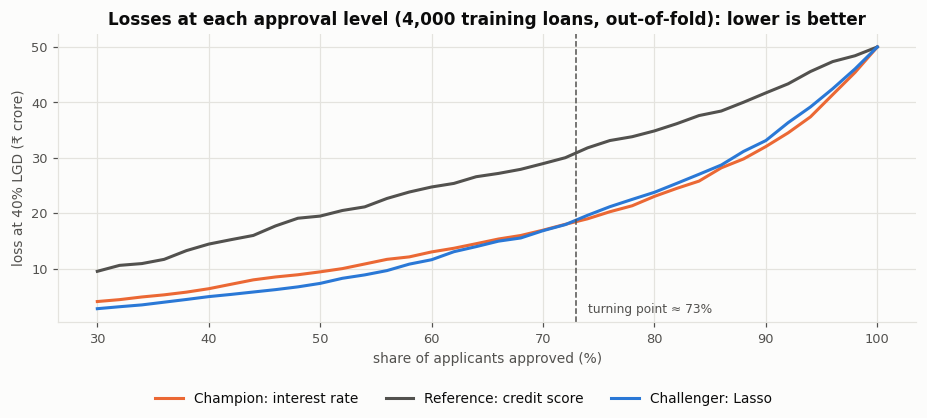

In [19]:
# (b) Same default rate, more lending: walk down the challenger's ranking until its running default
#     rate would exceed the champion's default rate at that level.
rows = []
for share in LEVELS:
    champ_idx = approve_safest(OOF[CHAMPION], share)
    target = y_train[champ_idx].mean()                                  # champion's default rate
    order = np.argsort(OOF[CHOSEN], kind="stable")
    running = np.cumsum(y_train[order]) / np.arange(1, len(order) + 1)   # default rate of the safest k loans
    k = int(np.max(np.where(running <= target)[0]) + 1)                  # most loans within that rate
    rows.append({"Champion approves": f"{share:.0%}", "Champion default rate": target,
                 "Champion loans": len(champ_idx), "Challenger loans at same rate": k,
                 "Extra loans": k - len(champ_idx),
                 "Extra ₹ lent (crore)": (amt[order[:k]].sum() - amt[champ_idx].sum()) / CRORE})
same_rate = pd.DataFrame(rows)
display(same_rate.style.format({"Champion default rate": "{:.1%}", "Extra ₹ lent (crore)": "{:+,.1f}"}))
save_table(same_rate, "rupee_same_default_rate")

# Chart: loss at 40% vs approval level, for every approval share from 30% to 100%.
grid = np.linspace(0.3, 1.0, 36)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for m, colour in [(CHAMPION, ORANGE), (REFERENCE, INK_2), (CHOSEN, BLUE)]:
    losses = [LGD * (amt[i] * y_train[i]).sum() / CRORE for i in (approve_safest(OOF[m], s) for s in grid)]
    ax.plot(grid * 100, losses, label=m if m != CHOSEN else f"Challenger: {m}", color=colour, lw=2)
ax.axvline(CROSSOVER * 100, color=INK_2, ls="--", lw=1)
ax.text(CROSSOVER * 100 + 1, 2, f"turning point ≈ {CROSSOVER:.0%}", fontsize=8, color=INK_2)
ax.set_xlabel("share of applicants approved (%)"); ax.set_ylabel("loss at 40% LGD (₹ crore)")
ax.set_title("Losses at each approval level (4,000 training loans, out-of-fold): lower is better")
fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.08, 1, 1))
save_chart(fig, "06_rupee_losses_by_approval")
plt.show()

In [20]:
# (c) Mispriced loans: the bank's price (rate above / below its median) against the challenger's PD.
rate = train.Interest_Rate.to_numpy()
median_rate = np.median(rate)
p_ch = OOF[CHOSEN]
groups = {
    "Priced as risky (rate ≥ median) but challenger PD < 10%": (rate >= median_rate) & (p_ch < 0.10),
    "Priced as safe (rate < median) but challenger PD > 30%": (rate < median_rate) & (p_ch > 0.30),
    "All training loans": np.ones(len(rate), bool),
}
mispriced = pd.DataFrame([{"Group": g, "Loans": int(mask.sum()), "Actual default rate": y_train[mask].mean(),
                           "Average rate charged (%)": rate[mask].mean(), "₹ lent (crore)": amt[mask].sum() / CRORE}
                          for g, mask in groups.items()])
display(mispriced.style.format({"Actual default rate": "{:.1%}", "Average rate charged (%)": "{:.2f}",
                                "₹ lent (crore)": "{:,.1f}"}))
save_table(mispriced, "mispriced_loans")
print(f"Median rate charged: {median_rate:.2f}%")

,Group,Loans,Actual default rate,Average rate charged (%),₹ lent (crore)
0,Priced as risky (rate ≥ median) but challenger PD < 10%,95,5.3%,9.59,8.2
1,Priced as safe (rate < median) but challenger PD > 30%,14,35.7%,8.82,1.6
2,All training loans,4000,20.0%,9.51,511.8


Median rate charged: 9.15%


## 8. The final exam: the 1,000 test loans

Now the chosen challenger and the champion (plus the reference) are trained **once** on all 4,000 training loans and score the 1,000 test loans **once**. Nothing about this step feeds back into any choice.

**Bootstrap 95% ranges.** The test set is one sample of 1,000 loans, so each number has an error bar:

```text
Repeat 1,000 times:
    draw 1,000 test loans at random WITH replacement (some twice, some not at all)
    recompute the measure (and the challenger − champion difference) on that draw
95% range = the 2.5th to 97.5th percentile of the 1,000 results
```

There is no retraining and no new data: it answers *"how much could this result move with a slightly different mix of applicants?"* If the range of the difference excludes 0, the gain is real.

**DeLong test:** the standard formula test for whether two ROC-AUCs measured on the same loans differ. It is a cross-check on the bootstrap for ROC-AUC.

In [21]:
final_models = {CHAMPION: single_input_model("Interest_Rate"), REFERENCE: single_input_model("Credit_Score"),
                CHOSEN: make_challengers()[CHOSEN]}
TEST_PD = {}
for m, model in final_models.items():
    model.fit(X_train, y_train)                      # trained once on all 4,000 training loans
    TEST_PD[m] = model.predict_proba(X_test)[:, 1]   # scored once on the 1,000 test loans
amt_test = test.Loan_Amount.to_numpy()


def loss_at(pd_scores, y, amounts, share=0.7):
    """Loss at 40% LGD (₹ crore) when approving the safest `share` of loans."""
    idx = approve_safest(pd_scores, share)
    return LGD * (amounts[idx] * y[idx]).sum() / CRORE


def test_measures(p, y, amounts):
    m = measures(y, p)
    return {k: m[k] for k in ["Brier", "ROC_AUC", "Gini", "KS", "Average_PD", "Calibration_slope", "Recall",
                              "Precision"]} | {"Loss at 70% approval (₹ crore)": loss_at(p, y, amounts)}


point = pd.DataFrame({m: test_measures(TEST_PD[m], y_test, amt_test) for m in final_models})

# Bootstrap: the same 1,000 resamples for every model, so the differences are paired.
rng = np.random.default_rng(SEED)
B = 1000
boot = {m: [] for m in final_models}
boot_diff = []
for _ in range(B):
    i = rng.integers(0, len(y_test), len(y_test))
    if y_test[i].min() == y_test[i].max():
        continue                                     # needs both outcomes (never happens with ~200 defaults)
    res = {m: test_measures(TEST_PD[m][i], y_test[i], amt_test[i]) for m in final_models}
    for m in final_models:
        boot[m].append(res[m])
    boot_diff.append({k: res[CHOSEN][k] - res[CHAMPION][k] for k in res[CHOSEN]})

test_tbl = []
for m in final_models:
    b = pd.DataFrame(boot[m])
    for k in point.index:
        test_tbl.append({"Model": m, "Measure": k, "Value": point.loc[k, m],
                         "95% low": b[k].quantile(0.025), "95% high": b[k].quantile(0.975)})
test_tbl = pd.DataFrame(test_tbl)
display(test_tbl.pivot(index="Measure", columns="Model", values="Value")[list(final_models)]
                .style.format("{:.4f}"))
save_table(test_tbl, "test_results")

Model,Champion: interest rate,Reference: credit score,Lasso
Measure,,,
Average_PD,0.2036,0.1992,0.2116
Brier,0.1432,0.1532,0.1406
Calibration_slope,1.0223,1.0619,1.1264
Gini,0.4370,0.2810,0.4829
KS,0.3469,0.2230,0.3824
Loss at 70% approval (₹ crore),4.0304,7.1205,4.2889
Precision,0.4222,0.3524,0.4009
ROC_AUC,0.7185,0.6405,0.7415
Recall,0.3819,0.1859,0.4372


,Challenger − champion,95% low,95% high,Verdict
Brier,-0.0025,-0.0063,+0.0010,Within the noise
ROC_AUC,+0.0230,-0.0022,+0.0472,Within the noise
Gini,+0.0459,-0.0044,+0.0945,Within the noise
KS,+0.0355,-0.0216,+0.0832,Within the noise
Average_PD,+0.0079,+0.0034,+0.0124,Information only
Calibration_slope,+0.1041,-0.0191,+0.2298,Information only
Recall,+0.0553,+0.0000,+0.1147,Within the noise
Precision,-0.0213,-0.0677,+0.0278,Within the noise
Loss at 70% approval (₹ crore),+0.2585,-0.7571,+0.9896,Within the noise


DeLong test: challenger ROC-AUC 0.741 vs champion 0.719, difference +0.023, p-value 0.0647
(p-value = chance of a gap this large if the two really ranked equally well; below 0.05 = a real difference)
Lasso: ROC-AUC training 0.737 → CV 0.731 → test 0.741


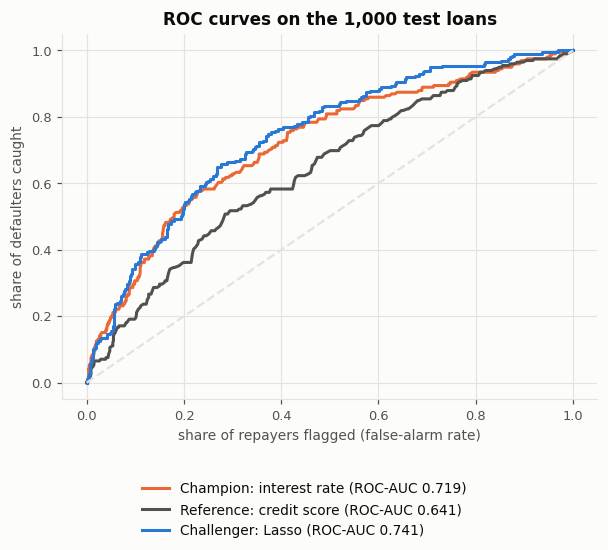

In [22]:
def delong(y, p1, p2):
    """DeLong test for two correlated ROC-AUCs on the same loans. Returns (AUC1, AUC2, difference, p-value).

    Idea: each defaulter's "placement" = share of repayers it outranks (and vice versa); the AUC is
    the average placement, and the variance of the difference comes from the placements' covariance.
    """
    pos, neg = y == 1, y == 0
    def placements(p):
        x, z = p[pos], p[neg]
        cmp = (x[:, None] > z[None, :]) + 0.5 * (x[:, None] == z[None, :])   # defaulter vs repayer, 1/0.5/0
        return cmp.mean(axis=1), cmp.mean(axis=0)                           # per defaulter, per repayer
    v10_1, v01_1 = placements(p1)
    v10_2, v01_2 = placements(p2)
    auc1, auc2 = v10_1.mean(), v10_2.mean()
    s10 = np.cov(np.vstack([v10_1, v10_2]))
    s01 = np.cov(np.vstack([v01_1, v01_2]))
    var = (s10[0, 0] + s10[1, 1] - 2 * s10[0, 1]) / pos.sum() + (s01[0, 0] + s01[1, 1] - 2 * s01[0, 1]) / neg.sum()
    z = (auc1 - auc2) / np.sqrt(var)
    return auc1, auc2, auc1 - auc2, 2 * stats.norm.sf(abs(z))


bd = pd.DataFrame(boot_diff)
diff_tbl = pd.DataFrame({
    "Challenger − champion": [point.loc[k, CHOSEN] - point.loc[k, CHAMPION] for k in point.index],
    "95% low": [bd[k].quantile(0.025) for k in point.index],
    "95% high": [bd[k].quantile(0.975) for k in point.index],
}, index=point.index)
better_high = {"ROC_AUC", "Gini", "KS", "Recall", "Precision"}
better_low = {"Brier", "Loss at 70% approval (₹ crore)"}
diff_tbl["Verdict"] = [
    ("Challenger better" if (k in better_high and r["95% low"] > 0) or (k in better_low and r["95% high"] < 0)
     else "Champion better" if (k in better_high and r["95% high"] < 0) or (k in better_low and r["95% low"] > 0)
     else "Within the noise" if k in better_high | better_low else "Information only")
    for k, r in diff_tbl.iterrows()]
display(diff_tbl.style.format("{:+.4f}", subset=["Challenger − champion", "95% low", "95% high"]))
save_table(diff_tbl.reset_index(names="Measure"), "test_challenger_vs_champion")

a1, a2, dauc, pval = delong(y_test, TEST_PD[CHOSEN], TEST_PD[CHAMPION])
print(f"DeLong test: challenger ROC-AUC {a1:.3f} vs champion {a2:.3f}, difference {dauc:+.3f}, p-value {pval:.4f}")
print("(p-value = chance of a gap this large if the two really ranked equally well; below 0.05 = a real difference)")

# Overfitting, end to end: training (CV rounds) → unseen in CV → unseen test.
print(f"{CHOSEN}: ROC-AUC training {over.loc[CHOSEN, 'Train_ROC_AUC']:.3f} → CV {over.loc[CHOSEN, 'CV_ROC_AUC']:.3f} "
      f"→ test {point.loc['ROC_AUC', CHOSEN]:.3f}")

fig, ax = plt.subplots(figsize=(5.6, 5))
for m, colour in [(CHAMPION, ORANGE), (REFERENCE, INK_2), (CHOSEN, BLUE)]:
    fpr, tpr, _ = roc_curve(y_test, TEST_PD[m])
    ax.plot(fpr, tpr, color=colour, lw=2, label=f"{m if m != CHOSEN else 'Challenger: ' + m} "
                                                f"(ROC-AUC {roc_auc_score(y_test, TEST_PD[m]):.3f})")
ax.plot([0, 1], [0, 1], color=GRID, ls="--")
ax.set_xlabel("share of repayers flagged (false-alarm rate)"); ax.set_ylabel("share of defaulters caught")
ax.set_title("ROC curves on the 1,000 test loans")
fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=1, frameon=False)
fig.tight_layout(rect=(0, 0.16, 1, 1))
save_chart(fig, "07_test_roc_curves")
plt.show()

## 8b. One model for both segments? Retail vs Corporate, and sector risk (decision M2-22)

The bank lends to two kinds of customer, and each loan carries a sector-risk score. A Board will ask: *do Retail and Corporate loans behave differently, does the model work for both, and would a separate model per segment do better?* This step tests each question.

**Note on "sector":** the data has no sector names, only `Sector_Risk`, a 0–100 score of the borrower's sector risk. So the sector view is by fifths of that score, not by industry.

| Question | Test | What would change our approach |
| --- | --- | --- |
| (a) Do the segments differ? | Default rate and borrower profile by segment; chi-square test. Default by fifth of sector risk; chi-square and trend test | A clear difference would call for segment-specific treatment |
| (b) Does one model work for both? | ROC-AUC, average PD vs actual, and predicted vs actual ₹ loss in each segment, out-of-fold and on the test loans | A segment where the model ranks or prices badly |
| (c) Would separate models do better? | Same 25 rounds: one lasso for all (chosen) vs one lasso per segment vs one lasso with segment interactions (each input allowed a different effect for Corporate). Paired 95% range of the Brier difference | A consistent Brier gain for a segment-specific model |

```text
Chi-square test: are default rates the same across groups? p < 0.05 → they differ
Trend test (correlation of Sector_Risk with Default_Flag): does default rise steadily with the score? p < 0.05 → yes
Interaction input = input × (1 if Corporate else 0): lets the model learn a different weight for Corporate
```

In [23]:
# (a) Do the segments differ?  Profiles on all 5,000 loans.
def segment_profile(t: pd.DataFrame) -> pd.Series:
    """Size, risk and pricing of one group of loans."""
    lent = t.Loan_Amount.sum()
    return pd.Series({"Loans": len(t), "₹ lent (crore)": lent / CRORE,
                      "Default rate": t.Default_Flag.mean(),
                      "Default rate (money)": (t.Default_Flag * t.Loan_Amount).sum() / lent,
                      "Average loan (₹ lakh)": t.Loan_Amount.mean() / 1e5,
                      "Interest rate (₹-weighted)": (t.Interest_Rate * t.Loan_Amount).sum() / lent / 100,
                      "Average credit score": t.Credit_Score.mean(), "Average debt-to-income": t.Debt_to_Income.mean(),
                      "Past default share": t.Past_Default.mean(),
                      "Interest − actual loss at 40% (crore)": ((t.Interest_Rate / 100 - LGD * t.Default_Flag)
                                                                 * t.Loan_Amount).sum() / CRORE})


seg_tbl = pd.DataFrame({g: segment_profile(t) for g, t in loans.groupby("Customer_Type")})
seg_tbl["Whole book"] = segment_profile(loans)
p_segment = stats.chi2_contingency(pd.crosstab(loans.Customer_Type, loans.Default_Flag))[1]
save_table(seg_tbl.T.round(4).reset_index(names="Segment"), "segment_profile")
display(seg_tbl.style.format("{:,.3f}"))
print(f"Retail vs Corporate default rate: chi-square p = {p_segment:.3f}")

# Sector risk: default by fifth of the score, overall and within each segment.
sector_fifth = pd.qcut(loans.Sector_Risk, 5, labels=["Lowest", "Low", "Middle", "High", "Highest"])
sector_tbl = loans.groupby([sector_fifth], observed=True).Default_Flag.mean().rename("All loans").to_frame()
by_seg = loans.groupby([sector_fifth, loans.Customer_Type.astype(str)], observed=True).Default_Flag.mean().unstack()
by_seg.columns = [str(c) for c in by_seg.columns]                     # plain column names (not categories)
sector_tbl = sector_tbl.join(by_seg)
p_sector = stats.chi2_contingency(pd.crosstab(sector_fifth, loans.Default_Flag))[1]
r_trend, p_trend = stats.pearsonr(loans.Sector_Risk, loans.Default_Flag)
save_table(sector_tbl.round(4).reset_index(names="Sector_Risk fifth"), "sector_risk_default")
display(sector_tbl.style.format("{:.1%}"))
print(f"Sector risk: fifths differ? chi-square p = {p_sector:.2f};  steady trend? correlation {r_trend:+.3f}, p = {p_trend:.3f}")

,Corporate,Retail,Whole book
Loans,"1,306.000","3,694.000","5,000.000"
₹ lent (crore),173.224,466.429,639.653
Default rate,0.200,0.199,0.199
Default rate (money),0.256,0.241,0.245
Average loan (₹ lakh),13.264,12.627,12.793
Interest rate (₹-weighted),0.104,0.103,0.103
Average credit score,687.743,688.926,688.617
Average debt-to-income,0.383,0.387,0.386
Past default share,0.112,0.111,0.111
Interest − actual loss at 40% (crore),0.247,2.828,3.075


Retail vs Corporate default rate: chi-square p = 0.995


,All loans,Corporate,Retail
Sector_Risk,,,
Lowest,18.2%,19.2%,17.8%
Low,19.5%,16.5%,20.6%
Middle,20.0%,19.6%,20.1%
High,21.3%,22.8%,20.8%
Highest,20.7%,21.9%,20.3%


Sector risk: fifths differ? chi-square p = 0.47;  steady trend? correlation +0.029, p = 0.042


In [24]:
# (b) Does one model work for both segments?  Honest PDs only: out-of-fold (training) and test.
seg_perf = []
for set_name, frame, pds in [("Training (out-of-fold)", train, OOF), ("Test (1,000)", test, TEST_PD)]:
    for g in ["Retail", "Corporate"]:
        m = (frame.Customer_Type == g).to_numpy()
        y_, amt_ = frame.Default_Flag.to_numpy()[m], frame.Loan_Amount.to_numpy()[m]
        p_ch, p_ci = pds[CHOSEN][m], pds[CHAMPION][m]
        seg_perf.append({"Set": set_name, "Segment": g, "Loans": int(m.sum()),
                         "ROC-AUC scorecard": roc_auc_score(y_, p_ch), "ROC-AUC champion": roc_auc_score(y_, p_ci),
                         "Brier scorecard": brier_score_loss(y_, p_ch), "Brier champion": brier_score_loss(y_, p_ci),
                         "Average PD": p_ch.mean(), "Actual default": y_.mean(),
                         "Predicted loss (crore)": (p_ch * LGD * amt_).sum() / CRORE,
                         "Actual loss (crore)": (y_ * LGD * amt_).sum() / CRORE})
seg_perf = pd.DataFrame(seg_perf)
seg_perf["ROC-AUC gain"] = seg_perf["ROC-AUC scorecard"] - seg_perf["ROC-AUC champion"]
save_table(seg_perf.round(4), "segment_model_performance")
seg_perf.style.format({c: "{:.3f}" for c in seg_perf.columns if "ROC" in c or "Brier" in c} |
                      {"Average PD": "{:.1%}", "Actual default": "{:.1%}", "Predicted loss (crore)": "₹{:.2f}",
                       "Actual loss (crore)": "₹{:.2f}"}).hide(axis="index")

Set,Segment,Loans,ROC-AUC scorecard,ROC-AUC champion,Brier scorecard,Brier champion,Average PD,Actual default,Predicted loss (crore),Actual loss (crore),ROC-AUC gain
Training (out-of-fold),Retail,2955,0.729,0.693,0.141,0.145,20.2%,19.9%,₹36.02,₹35.69,0.035
Training (out-of-fold),Corporate,1045,0.737,0.724,0.142,0.142,20.3%,20.0%,₹14.16,₹14.30,0.013
"Test (1,000)",Retail,739,0.740,0.702,0.140,0.143,21.1%,19.9%,₹9.47,₹9.31,0.038
"Test (1,000)",Corporate,261,0.745,0.763,0.142,0.143,21.2%,19.9%,₹3.39,₹3.42,-0.017


In [25]:
# (c) One model for all vs a model per segment vs one model with segment interactions (same 25 rounds).
lasso_settings = dict(Cs=10, penalty="l1", solver="liblinear", cv=INNER, scoring="neg_brier_score",
                      max_iter=5000, random_state=SEED)                       # exactly as the chosen lasso
INT_COLS = [f"{c} × Corporate" for c in NUM_INPUTS]
X_train_int = X_train.copy()
is_corp_train = (train.Customer_Type == "Corporate").to_numpy()
for c, ic in zip(NUM_INPUTS, INT_COLS):
    X_train_int[ic] = X_train[c] * is_corp_train                          # the input's extra effect for Corporate


def lasso_on(numbers):
    """A lasso pipeline on the given number inputs plus Customer_Type, tuned like the chosen model."""
    return Pipeline([("prep", make_preparation(numbers, CAT_INPUTS, scale=True)),
                     ("model", LogisticRegressionCV(**lasso_settings))])


seg_rounds = []
for r, (tr, te) in enumerate(SPLITS, start=1):
    y_te = y_train[te]
    p_one = lasso_on(NUM_INPUTS).fit(X_train.iloc[tr], y_train[tr]).predict_proba(X_train.iloc[te])[:, 1]
    p_sep = np.zeros(len(te))
    for flag in [True, False]:                                            # one lasso per segment
        a, b = tr[is_corp_train[tr] == flag], is_corp_train[te] == flag
        p_sep[b] = lasso_on(NUM_INPUTS).fit(X_train.iloc[a], y_train[a]).predict_proba(X_train.iloc[te[b]])[:, 1]
    p_int = (lasso_on(NUM_INPUTS + INT_COLS).fit(X_train_int.iloc[tr], y_train[tr])
             .predict_proba(X_train_int.iloc[te])[:, 1])
    for name, p in [("One model for both (chosen)", p_one), ("Separate model per segment", p_sep),
                    ("One model with segment interactions", p_int)]:
        seg_rounds.append({"Round": r, "Approach": name, "Brier": brier_score_loss(y_te, p),
                           "ROC_AUC": roc_auc_score(y_te, p)})
seg_rounds = pd.DataFrame(seg_rounds)

base = seg_rounds[seg_rounds.Approach == "One model for both (chosen)"].set_index("Round")
seg_cmp = []
for name, g in seg_rounds.groupby("Approach", sort=False):
    d_ = g.set_index("Round").Brier - base.Brier                        # positive = worse than one model
    half = T_CRIT * d_.std(ddof=1) / np.sqrt(len(d_)) if d_.std() > 0 else 0.0
    seg_cmp.append({"Approach": name, "Brier": g.Brier.mean(), "ROC-AUC": g.ROC_AUC.mean(),
                    "Brier vs one model": d_.mean(), "95% low": d_.mean() - half, "95% high": d_.mean() + half,
                    "Rounds worse than one model": int((d_ > 0).sum())})
seg_cmp = pd.DataFrame(seg_cmp)
save_table(seg_cmp.round(5), "segment_one_vs_separate_models")
ONE_MODEL_OK = bool((seg_cmp["Brier vs one model"].iloc[1:] >= -1e-4).all())   # no segment model clearly better
print("One model serves both segments (no segment-specific approach improves Brier):", ONE_MODEL_OK)
seg_cmp.style.format({"Brier": "{:.4f}", "ROC-AUC": "{:.3f}", "Brier vs one model": "{:+.4f}",
                      "95% low": "{:+.4f}", "95% high": "{:+.4f}"}).hide(axis="index")

One model serves both segments (no segment-specific approach improves Brier): True


Approach,Brier,ROC-AUC,Brier vs one model,95% low,95% high,Rounds worse than one model
One model for both (chosen),0.1411,0.731,+0.0000,+0.0000,+0.0000,0
Separate model per segment,0.1415,0.727,+0.0005,+0.0000,+0.0009,15
One model with segment interactions,0.1411,0.731,+0.0001,-0.0002,+0.0004,12


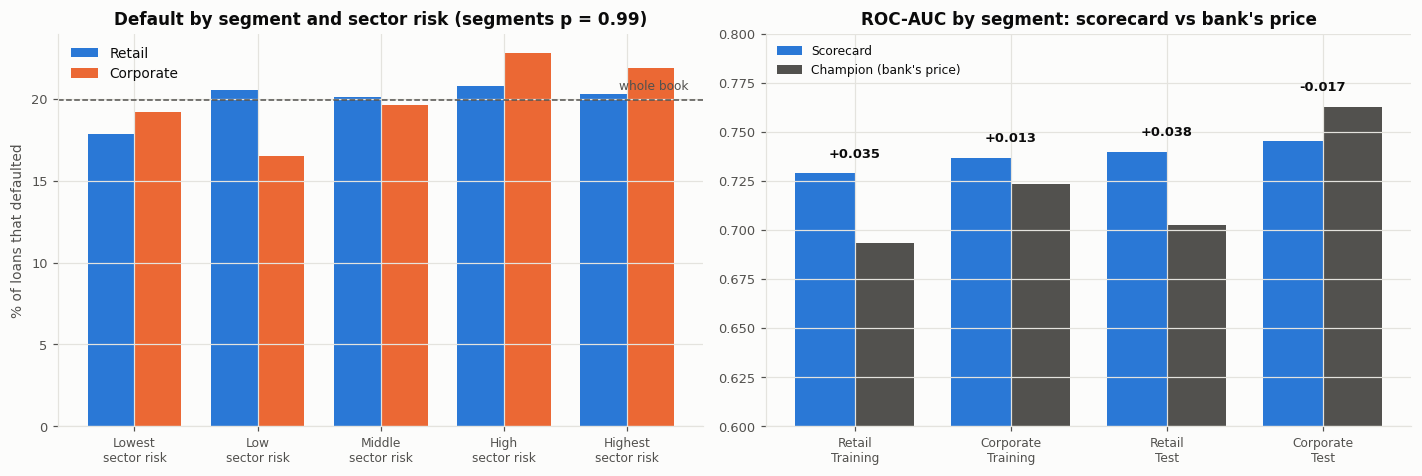

{'default_rate': {'Retail': 0.1992, 'Corporate': 0.1998}, 'segment_p': 0.995, 'sector_p': 0.472, 'sector_trend_p': 0.042, 'earn_crore': {'Retail': 2.83, 'Corporate': 0.25}, 'auc_gain_oof': {'Retail': 0.035, 'Corporate': 0.013}, 'brier_vs_one': {'One model for both (chosen)': 0.0, 'Separate model per segment': 0.0005, 'One model with segment interactions': 0.0001}, 'one_model_ok': True}


In [26]:
# Chart: default by segment and sector risk (left); ranking power by segment (right).
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
x = np.arange(len(sector_tbl))
for i, (g, colour) in enumerate([("Retail", BLUE), ("Corporate", ORANGE)]):
    axes[0].bar(x + (i - 0.5) * 0.38, sector_tbl[g] * 100, 0.38, color=colour, label=g)
axes[0].axhline(loans.Default_Flag.mean() * 100, color=INK_2, ls="--", lw=1)
axes[0].text(len(x) - 0.5, loans.Default_Flag.mean() * 100 + 0.6, "whole book", ha="right", fontsize=8, color=INK_2)
axes[0].set_xticks(x, [f"{f}\nsector risk" for f in sector_tbl.index], fontsize=8)
axes[0].set_ylabel("% of loans that defaulted"); axes[0].legend(frameon=False)
axes[0].set_title(f"Default by segment and sector risk (segments p = {p_segment:.2f})")

sp = seg_perf.set_index(["Set", "Segment"])
labels = [f"{g}\n{s_.split(' ')[0]}" for s_, g in sp.index]
xx = np.arange(len(sp))
axes[1].bar(xx - 0.19, sp["ROC-AUC scorecard"], 0.38, color=BLUE, label="Scorecard")
axes[1].bar(xx + 0.19, sp["ROC-AUC champion"], 0.38, color=INK_2, label="Champion (bank's price)")
for i, (a, b) in enumerate(zip(sp["ROC-AUC scorecard"], sp["ROC-AUC champion"])):
    axes[1].text(i, max(a, b) + 0.008, f"{a - b:+.3f}", ha="center", fontsize=8.5, fontweight="bold")
axes[1].set_xticks(xx, labels, fontsize=8); axes[1].set_ylim(0.6, 0.8); axes[1].legend(frameon=False, fontsize=8)
axes[1].set_title("ROC-AUC by segment: scorecard vs bank's price")
fig.tight_layout(); save_chart(fig, "10_segments"); plt.show()

SEG_KEY = {"default_rate": {g: round(float(seg_tbl.loc["Default rate", g]), 4) for g in ["Retail", "Corporate"]},
           "segment_p": round(float(p_segment), 3), "sector_p": round(float(p_sector), 3),
           "sector_trend_p": round(float(p_trend), 3),
           "earn_crore": {g: round(float(seg_tbl.loc["Interest − actual loss at 40% (crore)", g]), 2)
                          for g in ["Retail", "Corporate"]},
           "auc_gain_oof": {g: round(float(sp.loc[("Training (out-of-fold)", g), "ROC-AUC gain"]), 3)
                            for g in ["Retail", "Corporate"]},
           "brier_vs_one": {r.Approach: round(float(r["Brier vs one model"]), 4) for _, r in seg_cmp.iterrows()},
           "one_model_ok": ONE_MODEL_OK}
print(SEG_KEY)

## 9. Explaining the model: what drives default

A lending model must be explainable. The bank has to tell a refused borrower why, and show the regulator the model is sensible. Three views:

1. **Weights and odds ratios** (for a logistic-type model). The model is: log-odds of default = b0 + b1·z1 + … + bk·zk, where each input is standardised (z = (x − mean) ÷ standard deviation). So:
   ```text
   Odds ratio = e^b   →  how the odds of default multiply when the input rises by one standard deviation
   e.g. b = 0.50 → odds × 1.65 (65% higher); b = −0.50 → odds × 0.61 (39% lower); b = 0 → input switched off
   ```
2. **SHAP**: for each loan, how much each input pushed **that** loan's predicted risk up or down from the average. The pushes add up exactly to the loan's prediction (on the log-odds scale for logistic models).
3. **Example loans in ₹**: three test loans (low, middle and high PD), with what drove each one and the expected loss in rupees:
   ```text
   Expected loss (₹) = PD × 40% × Loan_Amount
   ```

All fitted on the 4,000 training loans (the model from step 8) and shown on the test loans.

In [27]:
final = final_models[CHOSEN]
prep, est = final.named_steps["prep"], final.named_steps["model"]
feature_names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
inner = est.best_estimator_ if hasattr(est, "best_estimator_") else est     # unwrap a tuned model
IS_LINEAR = hasattr(inner, "coef_")

if IS_LINEAR:
    coef = pd.DataFrame({"Input": feature_names, "Weight b (per 1 std)": inner.coef_[0]})
    coef["Odds ratio e^b"] = np.exp(coef["Weight b (per 1 std)"])
    coef["Effect on default odds"] = [
        "switched off (weight 0)" if b == 0 else f"{'raises' if b > 0 else 'lowers'} odds by {abs(np.exp(b) - 1):.0%}"
        for b in coef["Weight b (per 1 std)"]]
    coef = coef.reindex(coef["Weight b (per 1 std)"].abs().sort_values(ascending=False).index).reset_index(drop=True)
    display(coef.style.format({"Weight b (per 1 std)": "{:+.3f}", "Odds ratio e^b": "{:.2f}"}))
    save_table(coef, "model_weights_odds_ratios")
    if hasattr(inner, "C_"):
        print(f"Lasso penalty chosen by inner CV on the 4,000 loans: C = {inner.C_[0]:.4f} "
              f"(λ = 1 ÷ C = {1 / inner.C_[0]:.2f}); inputs kept: {(coef['Weight b (per 1 std)'] != 0).sum()} of {len(coef)}")
else:
    imp = pd.DataFrame({"Input": feature_names, "Importance": inner.feature_importances_})
    display(imp.sort_values("Importance", ascending=False).reset_index(drop=True))
    save_table(imp, "model_importances")

,Input,Weight b (per 1 std),Odds ratio e^b,Effect on default odds
0,Credit_Score,-0.451,0.64,lowers odds by 36%
1,Debt_to_Income,+0.423,1.53,raises odds by 53%
2,Past_Default,+0.338,1.40,raises odds by 40%
3,Loan_Amount,+0.159,1.17,raises odds by 17%
4,Loan_to_Income,+0.121,1.13,raises odds by 13%
5,Total_Debt_to_Income,+0.111,1.12,raises odds by 12%
6,Collateral_Value,+0.037,1.04,raises odds by 4%
7,Loan_Term_Months,+0.000,1.00,switched off (weight 0)
8,Existing_Loan,+0.000,1.00,switched off (weight 0)
9,Annual_Income,+0.000,1.00,switched off (weight 0)


Lasso penalty chosen by inner CV on the 4,000 loans: C = 0.0464 (λ = 1 ÷ C = 21.54); inputs kept: 7 of 15


,Input,Mean |SHAP|
0,Credit_Score,0.367
1,Debt_to_Income,0.348
2,Past_Default,0.213
3,Loan_Amount,0.112
4,Loan_to_Income,0.105
5,Total_Debt_to_Income,0.094
6,Collateral_Value,0.024
7,Loan_Term_Months,0.000
8,Existing_Loan,0.000
9,Annual_Income,0.000


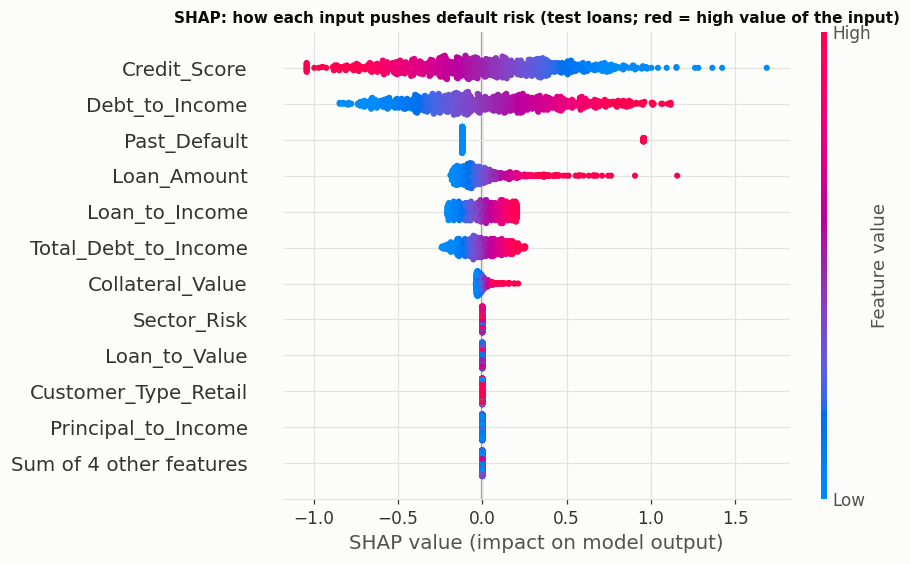

In [28]:
# SHAP values on the 1,000 test loans.
Z_train = prep.transform(X_train)
Z_test = prep.transform(X_test)
if IS_LINEAR:
    # exact for linear models (log-odds scale); the masker uses all 4,000 training loans as the "average loan"
    explainer = shap.LinearExplainer(inner, shap.maskers.Independent(Z_train, max_samples=len(Z_train)))
else:
    explainer = shap.TreeExplainer(inner)                       # exact for tree models
sv = explainer(Z_test)
if sv.values.ndim == 3:                                         # some tree models return both classes
    sv = sv[:, :, 1]
sv.feature_names = feature_names

shap_rank = (pd.DataFrame({"Input": feature_names, "Mean |SHAP|": np.abs(sv.values).mean(axis=0)})
               .sort_values("Mean |SHAP|", ascending=False).reset_index(drop=True))
display(shap_rank.style.format({"Mean |SHAP|": "{:.3f}"}))
save_table(shap_rank, "shap_importance")

plt.figure()
np.random.seed(SEED)                        # SHAP places overlapping dots at random: fixed so reruns draw the same chart
shap.plots.beeswarm(sv, max_display=12, show=False)
fig = plt.gcf(); fig.set_size_inches(8.5, 5.2)
plt.title("SHAP: how each input pushes default risk (test loans; red = high value of the input)", fontsize=10)
plt.tight_layout()
save_chart(fig, "08_shap_summary")
plt.show()

,Example,Loan_ID,Customer_Type,Loan (₹ lakh),Credit_Score,Debt_to_Income,Past_Default,Rate charged (%),Champion PD,Challenger PD,Expected loss (₹ lakh),Actually defaulted?,Top 3 drivers (SHAP push)
0,Low risk,200656,Retail,2.0,820,0.33,0,7.56,10.1%,4.9%,0.04,No,Credit_Score -0.85; Loan_Amount -0.16; Loan_to_Income -0.13
1,Middle,201102,Corporate,1.1,755,0.42,1,9.89,19.8%,17.9%,0.08,No,Past_Default +0.96; Credit_Score -0.43; Total_Debt_to_Income -0.22
2,High risk,201025,Retail,22.8,540,0.09,1,15.38,61.0%,56.7%,5.18,Yes,Credit_Score +0.96; Past_Default +0.96; Debt_to_Income -0.70


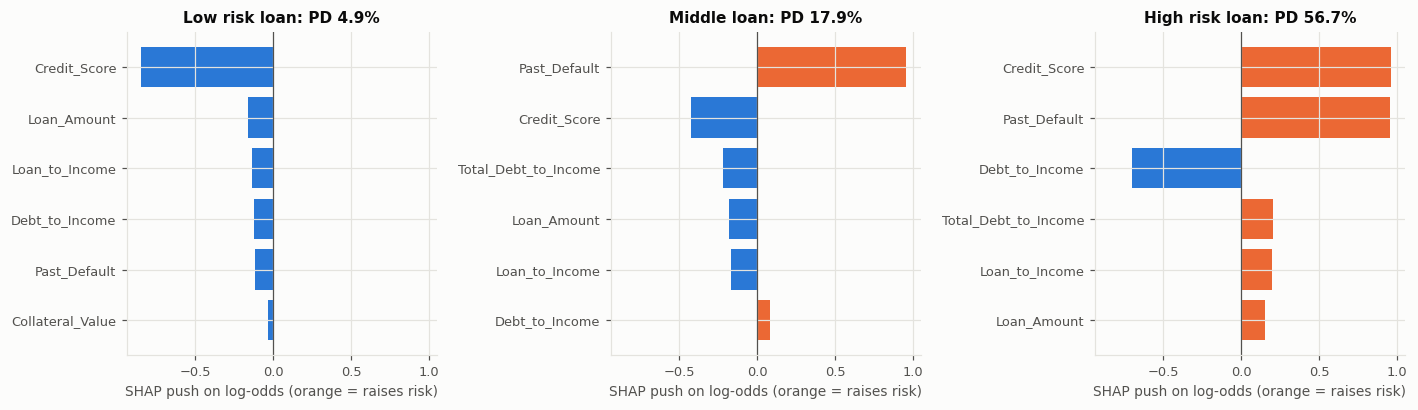

In [29]:
# Three example test loans: the lowest, the middle and the highest challenger PD.
order = np.argsort(TEST_PD[CHOSEN])
examples = {"Low risk": order[len(order) // 50], "Middle": order[len(order) // 2], "High risk": order[-len(order) // 50]}
rows, fig_rows = [], []
for label, i in examples.items():
    loan = test.iloc[i]
    contrib = pd.Series(sv.values[i], index=feature_names)
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index)[:3]
    rows.append({
        "Example": label, "Loan_ID": int(loan.Loan_ID), "Customer_Type": loan.Customer_Type,
        "Loan (₹ lakh)": loan.Loan_Amount / LAKH, "Credit_Score": int(loan.Credit_Score),
        "Debt_to_Income": loan.Debt_to_Income, "Past_Default": int(loan.Past_Default),
        "Rate charged (%)": loan.Interest_Rate, "Champion PD": TEST_PD[CHAMPION][i], "Challenger PD": TEST_PD[CHOSEN][i],
        "Expected loss (₹ lakh)": TEST_PD[CHOSEN][i] * LGD * loan.Loan_Amount / LAKH,
        "Actually defaulted?": "Yes" if loan.Default_Flag == 1 else "No",
        "Top 3 drivers (SHAP push)": "; ".join(f"{k} {v:+.2f}" for k, v in top.items()),
    })
    fig_rows.append((label, contrib))
example_tbl = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", None):
    display(example_tbl.style.format({"Loan (₹ lakh)": "{:.1f}", "Debt_to_Income": "{:.2f}", "Rate charged (%)": "{:.2f}",
                                      "Champion PD": "{:.1%}", "Challenger PD": "{:.1%}",
                                      "Expected loss (₹ lakh)": "{:.2f}"}))
save_table(example_tbl, "example_loans")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True)
for ax, (label, contrib) in zip(axes, fig_rows):
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index)[:6][::-1]
    ax.barh(top.index, top.values, color=[ORANGE if v > 0 else BLUE for v in top.values])
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.set_title(f"{label} loan: PD {TEST_PD[CHOSEN][examples[label]]:.1%}", fontsize=10)
    ax.set_xlabel("SHAP push on log-odds (orange = raises risk)")
fig.tight_layout()
save_chart(fig, "09_example_loans_shap")
plt.show()

## 10. What the results say

### The data (step 1)
- **The book:** 5,000 loans, **₹639.7 crore** lent, 19.9% defaulted. By money, though, **24.5%** of the ₹ went to borrowers who defaulted: defaulted loans average ₹15.7 lakh against ₹12.1 lakh for repaid loans. At 40% LGD, today's book carries **₹62.7 crore of losses (9.8% of the book)**. Retail and Corporate default at the same rate (20.0% vs 19.9%).
- **The strongest links:**
  - Interest_Rate: 8.5% → 41.9% default from the cheapest to the dearest fifth, which is why the bank's price is a strong champion;
  - Credit_Score: 31.8% → 10.0%;
  - Debt_to_Income: 11.4% → 32.5%;
  - Past_Default: 37.8% vs 17.7%;
  - Loan_Amount: 13.3% → 31.0%.
- **Collateral doesn't predict default.** Default runs 17.6%–21.9% across the cover fifths, and the 1,665 under-collateralised loans (₹212.7 crore) default *less* (18.5% vs 20.7%). Collateral matters for **how much is lost**, which is a Task 3 matter.
- **Loan term doesn't affect default** (19.1%–20.8% across 1–7 years). So Default_Flag behaves like a one-year default measure, which supports the one-year view planned for Task 3.

### The ML case (steps 5–6)

| 25-round CV, 4,000 loans | Brier ↓ | ROC-AUC ↑ | KS ↑ | Overfitting gap |
| --- | --- | --- | --- | --- |
| Champion: interest rate | 0.1444 | 0.702 | 0.322 | 0.000 |
| Reference: credit score | 0.1542 | 0.632 | 0.213 | 0.000 |
| **Lasso (chosen)** | **0.1411** | **0.731** | **0.363** | 0.006 |
| Logistic regression | 0.1413 | 0.730 | 0.363 | 0.007 |
| Decision tree | 0.1494 | 0.679 | 0.289 | 0.049 |
| Random forest | 0.1442 | 0.718 | 0.344 | **0.133: ruled out** |
| LightGBM | 0.1445 | 0.716 | 0.341 | **0.109: ruled out** |

The selection rule, applied step by step:
1. Random forest and LightGBM **memorise** their training loans (ROC-AUC 0.85 / 0.83 on training vs 0.72 unseen), so they are ruled out. This is the overfitting lesson from Module 1 again.
   - **The rejection doesn't rest on this check alone.** Judged only on unseen loans, both still lose to lasso in nearly every round: Brier worse by +0.0032 / +0.0034 (lasso better in 25 / 24 of 25 rounds) and ROC-AUC lower by 0.013 / 0.015 (lasso better in 22 / 24 of 25).
   - The choice also doesn't depend on the exact 0.05 limit: any limit from 0.05 to 0.10 rules out the same two models.
2. **Lasso has the best Brier score.**
3. Plain logistic regression is a hair behind (0.1413). The gap is tiny but consistent across rounds, so it isn't a tie.
4. **Against the champion, lasso wins in every round on ROC-AUC (25 of 25) and in 24 of 25 on Brier.** The paired 95% ranges are well clear of zero: ROC-AUC +0.024 to +0.034, Brier −0.0040 to −0.0026.

**What lasso keeps:** 7 of 15 inputs. Credit_Score lowers the odds of default by 36% per standard deviation. Debt_to_Income raises them by 53%, Past_Default by 40%, Loan_Amount by 17%, Loan_to_Income by 13%, Total_Debt_to_Income by 12%, and Collateral_Value by 4%. Collateral_Value appears because bigger collateral comes with bigger loans; it is not cheaper collateral causing default.
- Sector_Risk, Employment_Length, Annual_Income, Existing_Loan, Loan_Term_Months, Loan_to_Value, Principal_to_Income and Customer_Type are **switched off (weight 0)**. This matches step 1, where their default rates were flat.
- The result is a **7-input scorecard** a credit officer can read.

**The fundamentals already explain 72% of the bank's rate.** So the challenger is competing for the remaining slice, and that's why its edge is real but modest.

### The finance case (step 7, in ₹, out-of-fold on 4,000 loans)

| Approve the safest | Champion: defaults / loss | Lasso: defaults / loss | Lasso saves |
| --- | --- | --- | --- |
| 50% | 225 / ₹9.42 crore | 188 / ₹7.33 crore | **37 defaults, ₹2.08 crore** |
| 60% | 294 / ₹13.01 crore | 262 / ₹11.60 crore | **32 defaults, ₹1.41 crore** |
| 70% | 367 / ₹16.94 crore | 342 / ₹16.84 crore | 25 defaults, ₹0.09 crore |
| 80% | 465 / ₹23.04 crore | 451 / ₹23.77 crore | 14 fewer defaults, but ₹0.74 crore *more* loss |
| 90% | 595 / ₹32.03 crore | 590 / ₹33.11 crore | 5 fewer defaults, but ₹1.08 crore *more* loss |

- **Where the ₹ advantage turns (the sweep across every approval level from 30% to 100%):**

  | When the bank approves | Lasso loses less money? | Average saving per 4,000 applicants |
  | --- | --- | --- |
  | 30% to 72% of applicants | **Yes, at all 43 levels** | **+₹1.37 crore** |
  | 73% to 79% | No, at all 7 levels | −₹0.88 crore |
  | 80% to 100% | **No, at all 21 levels** | −₹1.08 crore |

  - The value is concentrated where the bank is **selective**. The **turning point is about 73% approval**.
  - Above it, lasso still lets through fewer defaulters, but it approves a larger book in ₹ (₹361 vs ₹352 crore at 80%). So the defaults it lets through are bigger loans, and the ₹ loss is slightly higher.
  - Which approval level the bank uses is a Task 3 decision, so this turning point is carried to Task 3.
- **Lend more at the same risk:** holding the champion's default rate, lasso approves **465 more loans (+₹60.0 crore) at the 50% level and 215 more (+₹38.1 crore) at 70%**.
- **Mispricing found:**
  - **95 loans (₹8.2 crore) are priced as risky** (rate at or above the 9.15% median, average 9.6%) **but lasso gives them under 10% PD, and only 5.3% defaulted.** These are good customers being overcharged: the bank could win more of this business at a fair price.
  - **14 loans (₹1.6 crore) are priced as safe but lasso gives them over 30% PD: 35.7% defaulted.**

### The final exam (step 8: 1,000 test loans, used once)

| Measure | Champion | Lasso | Lasso − champion | 95% range (bootstrap) |
| --- | --- | --- | --- | --- |
| ROC-AUC | 0.719 | 0.741 | +0.023 | −0.002 to +0.047 |
| Brier | 0.1432 | 0.1406 | −0.0025 | −0.0063 to +0.0010 |
| KS | 0.347 | 0.382 | +0.036 | −0.022 to +0.083 |
| Recall at 30% PD | 38.2% | 43.7% | +5.5 points | 0.0 to +11.5 points |
| Loss at 70% approval | ₹4.03 crore | ₹4.29 crore | +₹0.26 crore | −₹0.76 to +₹0.99 crore |

- **The ranking, probability and recall measures point the same way as in cross-validation**: lasso ranks better, has better PDs and catches more defaulters.
- **But on 1,000 loans (199 defaults) the gain is not proven at the 95% level.** Every range includes or reaches zero. The DeLong test gives p = 0.065, just above the usual 0.05 line.
- The ₹ loss at 70% approval is within the noise either way.
- **No overfitting:** lasso's ROC-AUC is 0.737 on training, 0.731 in CV and 0.741 on test.

### Segments: one model for both Retail and Corporate? (step 8b, decision M2-22)

**(a) The segments don't differ.**

| | Retail | Corporate |
| --- | --- | --- |
| Loans, ₹ lent | 3,694, ₹466.4 crore | 1,306, ₹173.2 crore |
| Default rate (by count / by money) | 19.9% / 24.1% | 20.0% / 25.6% |
| Average credit score, debt-to-income, past default | 689, 0.39, 11.1% | 688, 0.38, 11.2% |
| Interest rate (₹-weighted) | 10.25% | 10.37% |

- Default rate: chi-square p = 0.995, no difference. The borrower profiles are nearly identical.
- **Sector risk** (a 0–100 score; the data has no sector names): default rises only from 18.2% (lowest fifth) to 20.7–21.3% (two highest). The fifths don't differ significantly (p = 0.47), though there is a weak steady trend (p = 0.04). The lasso judged it adds nothing beyond credit score and debt-to-income.

**(b) The model works in both segments.**

| | ROC-AUC scorecard | ROC-AUC bank's price | Brier scorecard vs bank's price | Predicted vs actual loss |
| --- | --- | --- | --- | --- |
| Retail, out-of-fold (2,955) | **0.729** | 0.693 | 0.1406 vs 0.1450 | ₹36.0 vs ₹35.7 crore |
| Corporate, out-of-fold (1,045) | 0.737 | 0.724 | 0.1419 vs 0.1425 | ₹14.2 vs ₹14.3 crore |
| Retail, test (739) | **0.740** | 0.702 | 0.1401 vs 0.1431 | ₹9.5 vs ₹9.3 crore |
| Corporate, test (261) | 0.746 | **0.763** | 0.1422 vs 0.1435 | ₹3.4 vs ₹3.4 crore |

- **Calibrated in both segments:** predicted loss matches actual within ₹0.4 crore everywhere.
- **The ranking gain comes mostly from Retail** (+0.035 out-of-fold, +0.038 test). In Corporate the bank's price ranks about as well (+0.013 out-of-fold, −0.017 on only 261 test loans). The scorecard's Brier is still better in every segment, because its PDs are better calibrated.

**(c) A separate model per segment does worse.**

| Approach (same 25 rounds) | Brier | ROC-AUC | Brier vs one model (95% range) | Rounds worse |
| --- | --- | --- | --- | --- |
| **One model for both (chosen)** | **0.1411** | **0.731** | — | — |
| Separate model per segment | 0.1415 | 0.727 | +0.0005 (+0.0001 to +0.0009) | 15 of 25 |
| One model with segment interactions | 0.1412 | 0.731 | +0.0001 (−0.0002 to +0.0004) | 12 of 25 |

- A model per segment is **worse beyond chance** (the whole range is above 0): each half has fewer loans to learn from, and there is no segment difference to gain.
- Letting one model weigh each input differently for Corporate gains nothing (a tie).
- **So one model for both segments is the right choice, on evidence.** Customer_Type stays an input; the lasso switches it off because it carries no information here.

### The honest verdict for the Board
- **ML:** a 7-input lasso scorecard on borrower fundamentals **ranks default risk better than the bank's own pricing**: +0.029 ROC-AUC, winning all 25 CV rounds, with the same direction on the test set. Its PDs are well calibrated in CV (average 20.2% vs actual 20.0%, slope 1.03). It doesn't overfit, and it is fully explainable.
- **Finance:** the gain is **modest and selective**. When the bank lends to the safest half of applicants, the scorecard avoids about 37 defaults and ₹2.1 crore of loss per 4,000 applicants, or lends ₹60 crore more at the same default rate. It also identifies **mispriced** loans. When the bank lends to almost everyone, it adds little.
- **What it doesn't do:** it doesn't replace pricing. The bank's rate already captures 72% of what the fundamentals say. The test set is too small to prove the gain beyond doubt, so the scorecard's value should be confirmed on new applications before it carries weight alone.

### What goes to Task 2
- `outputs/task1/FINAL_M2_T1_default_predictions.csv`: for every Loan_ID, the lasso PD and the champion PD. Training loans carry out-of-fold PDs, test loans carry test PDs, so no loan is scored by a model that saw it.
- `chosen_model.joblib`: the lasso scorecard (C = 0.046, 7 inputs).
- Task 2 checks whether these PDs can be trusted as probabilities (calibration), then tests the brief's risk bands.

In [30]:
# The key numbers behind the findings above, recomputed so they always match this run.
key = {
    "loans": len(loans), "default_rate": round(float(y_all.mean()), 4),
    "default_rate_money": round(float(board.loc["Default rate (money)", "Whole book"]), 4),
    "book_crore": round(float(loans.Loan_Amount.sum() / CRORE), 1),
    "loss_at_40_crore": round(float(board.loc["Loss at 40% LGD (crore)", "Whole book"]), 1),
    "under_collateralised": int(under.sum()), "rate_r2_on_fundamentals": round(float(r2), 3),
    "chosen": CHOSEN, "ruled_out_overfitting": ruled_out,
    "cv": {m: {"Brier": round(float(mean_tbl.loc[m, "Brier"]), 4), "ROC_AUC": round(float(mean_tbl.loc[m, "ROC_AUC"]), 3),
               "KS": round(float(mean_tbl.loc[m, "KS"]), 3)} for m in MODEL_ORDER},
    "rupee_turning_point": CROSSOVER,
    "rupee_saving_by_range": {r["Approval levels"]: round(float(r["Average saving (₹ crore)"]), 2)
                              for _, r in sweep_tbl.iterrows()},
    "test": {m: {k: round(float(point.loc[k, m]), 4) for k in point.index} for m in final_models},
    "test_diff": {k: [round(float(v), 4) for v in diff_tbl.loc[k, ["Challenger − champion", "95% low", "95% high"]]]
                  for k in diff_tbl.index},
    "delong_p": round(float(pval), 4),
    "segments": SEG_KEY,
}
print(json.dumps({k: key[k] for k in ["chosen", "rupee_turning_point", "delong_p"]}, indent=1))

{
 "chosen": "Lasso",
 "rupee_turning_point": 0.73,
 "delong_p": 0.0647
}


## 11. Save the outputs

Everything goes to `outputs/task1/`:
- the tables and charts above;
- `FINAL_M2_T1_default_predictions.csv`: one row per loan with Loan_ID, which set it is in (training or test), Default_Flag, the champion's PD and the chosen challenger's PD. Training loans carry their **out-of-fold** PD and test loans their **test** PD, so no loan is scored by a model that saw it. Task 2 starts from this file;
- `chosen_model.joblib`: the chosen challenger, fitted on the 4,000 training loans;
- `chosen_model.json`: its name, settings and inputs;
- `key_numbers.json`: the headline numbers of this run.

In [31]:
pred = pd.concat([
    pd.DataFrame({"Loan_ID": train.Loan_ID, "Set": "train (out-of-fold)", "Default_Flag": y_train,
                  "PD_champion": OOF[CHAMPION], "PD_challenger": OOF[CHOSEN]}),
    pd.DataFrame({"Loan_ID": test.Loan_ID, "Set": "test", "Default_Flag": y_test,
                  "PD_champion": TEST_PD[CHAMPION], "PD_challenger": TEST_PD[CHOSEN]}),
]).sort_values("Loan_ID").reset_index(drop=True)
assert pred.Loan_ID.is_unique and len(pred) == len(loans)
save_table(pred.round(6), "FINAL_M2_T1_default_predictions")

joblib.dump(final, OUT_DIR / "chosen_model.joblib")
settings = {"name": CHOSEN, "inputs": MODEL_INPUTS, "interest_rate_used": False, "trained_on": "4,000 training loans",
            "seed": SEED}
if IS_LINEAR and hasattr(inner, "C_"):
    settings["lasso_C"] = float(inner.C_[0])
if hasattr(est, "best_params_"):
    settings["tuned"] = est.best_params_
(OUT_DIR / "chosen_model.json").write_text(json.dumps(settings, indent=1), encoding="utf-8")
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=1), encoding="utf-8")
print("Saved to", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())
print(sorted(p.name for p in OUT_DIR.iterdir()))

Saved to module_02_credit_risk/outputs/task1
['01_default_rate_by_input.png', '02_loan_book_board_view.png', '03_collateral_and_term.png', '04_cv_comparison.png', '05_overfitting_check.png', '06_rupee_losses_by_approval.png', '07_test_roc_curves.png', '08_shap_summary.png', '09_example_loans_shap.png', '10_segments.png', 'FINAL_M2_T1_default_predictions.csv', 'all_models_vs_chosen.csv', 'chosen_model.joblib', 'chosen_model.json', 'collateral_cover.csv', 'cv_rounds.csv', 'cv_summary.csv', 'default_by_term.csv', 'default_rate_by_input.csv', 'example_loans.csv', 'key_numbers.json', 'loan_book_board_view.csv', 'mispriced_loans.csv', 'model_inputs.csv', 'model_weights_odds_ratios.csv', 'overfitting_check.csv', 'paired_vs_best.csv', 'paired_vs_champion.csv', 'rebalancing_evidence.csv', 'rupee_same_approval.csv', 'rupee_same_default_rate.csv', 'rupee_sweep.csv', 'sector_risk_default.csv', 'segment_model_performance.csv', 'segment_one_vs_separate_models.csv', 'segment_profile.csv', 'shap_impor